# 구리 시장의 시간차 인과 구조 — 최소 프로토타입

**최신 변수·파라미터·분석창 탐색과 결과 해석은 10절에 있습니다.** 1–9절은 비교 기준인 최초 고정 분석을 보존합니다.

**주 타깃:** LME 구리 3개월물. 달러지수·브렌트유·LME 구리 재고를 함께 분석합니다.

이 Notebook은 보유 CSV의 **월간 로그변화율**에서 관계를 탐색합니다. 원자료의 장기 가격수준 관계, 인과효과의 크기, 가격예측을 추정하지 않습니다. 3개월물은 해당 관측월의 가격이며, 만기가 3개월이라는 이유로 관측치를 미래로 이동하지 않습니다.

흐름: 데이터 점검 → 전처리·사전 제약 → LPCMCI → PAG·상류 경로 → 설정별 안정성 → Codex 도메인 검토.
원래 PAG와 LLM의 추가 가정을 구분하고, 미확정·잠재교란·빈 그래프도 결과로 보존합니다.

재실행: 프로젝트의 `.venv` Python을 커널로 선택하거나 터미널에서 `.venv/bin/python run_notebook.py`를 실행합니다. 환경 재구성은 `uv pip install --python .venv/bin/python -r requirements.txt`입니다. 외부 LLM API 호출은 없습니다.

In [1]:
from pathlib import Path
from hashlib import sha256
from importlib.metadata import PackageNotFoundError, version
import sys
import warnings

ROOT = Path.cwd()
EXPECTED_PREFIX = ROOT / '.venv'
if Path(sys.prefix).resolve() != EXPECTED_PREFIX.resolve():
    raise RuntimeError(
        '커널 불일치: Notebook 우측 상단에서 Python (causal_study .venv)를 선택한 뒤 다시 실행하세요. '
        f'현재 Python: {sys.executable}; 필요한 Python: {EXPECTED_PREFIX / "bin" / "python"}'
    )
REQUIRED_PACKAGES = ['tigramite', 'numpy', 'scipy', 'pandas', 'statsmodels', 'joblib', 'matplotlib', 'networkx']
missing_packages = []
for package in REQUIRED_PACKAGES:
    try:
        version(package)
    except PackageNotFoundError:
        missing_packages.append(package)
if missing_packages:
    raise RuntimeError(
        f'프로젝트 환경에 패키지가 없습니다: {missing_packages}. '
        '프로젝트 터미널에서 uv pip install --python .venv/bin/python -r requirements.txt 로 복원하세요.'
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from causal_graph import edge_table, upstream_paths, review_graph, plot_pag

DATA_PATH = ROOT / "data" / "com_copper_raw.csv"
assert DATA_PATH.is_file(), "프로젝트 루트에서 Notebook을 실행하세요."
INPUT_HASH = sha256(DATA_PATH.read_bytes()).hexdigest()
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.precision", 5)
display(pd.DataFrame({
    "package": ["Python", "tigramite", "numpy", "scipy", "pandas", "statsmodels", "joblib"],
    "version": [sys.version.split()[0]] + [
        version(p) for p in ["tigramite", "numpy", "scipy", "pandas", "statsmodels", "joblib"]
    ],
}))


,package,version
0,Python,3.13.5
1,tigramite,5.2.10.1
2,numpy,2.5.3
3,scipy,1.18.1
4,pandas,3.0.5
5,statsmodels,0.15.0
6,joblib,1.6.0


## 0. Notebook 내부 분석 정의

데이터 처리와 LPCMCI 실행 로직을 단계별 코드 셀에 직접 정의합니다. 그래프 표시·경로 탐색·검토 검증만 `causal_graph.py`에서 가져옵니다. 아래 정의 셀까지 포함해 위에서부터 전체 실행하세요.

In [2]:
"""Core data preparation and LPCMCI routines for the copper prototype.

The module deliberately keeps discovery output separate from interpretation.
In particular, Tigramite's ``p_matrix`` contains the largest conditional-
independence p-value encountered for an adjacency and ``val_matrix`` contains
the associated partial-correlation statistic.  Neither is an effect size,
direction confidence, or posterior probability.
"""

from __future__ import annotations

from dataclasses import asdict, dataclass, field
from hashlib import sha256
from importlib.metadata import PackageNotFoundError, version
import json
from pathlib import Path
import platform
import time
from typing import Any, Iterable, Mapping, Sequence
import warnings

import numpy as np
import pandas as pd


TARGET = "Com_LME_Cu_3M"
CASH_TARGET = "Com_LME_Cu_Cash"
EXPLANATORY = ("Idx_DxyUSD", "Com_BrentCrudeOil", "Com_LME_Cu_Inv")
VARIABLES = [TARGET, *EXPLANATORY]
DATE_COLUMN = "dt"
REFERENCE_BURN = 6
SEED = 0


@dataclass
class RunConfig:
    """One discovery configuration.

    ``delays`` are explicit assumed publication delays measured in whole
    months.  They are hypotheses because the source CSV has no release-date or
    vintage information; they must not be described as verified point-in-time
    availability.
    """

    name: str
    target: str = TARGET
    start: str | pd.Timestamp | None = None
    end: str | pd.Timestamp | None = None
    tau_max: int = 2
    pc_alpha: float = 0.05
    delays: dict[str, int] = field(default_factory=dict)


@dataclass
class RunResult:
    name: str
    target: str
    variables: list[str]
    config: dict[str, Any]
    frame: pd.DataFrame
    graph: np.ndarray
    val_matrix: np.ndarray
    p_matrix: np.ndarray
    signature: str
    metadata: dict[str, Any]


def _iso_month(value: Any) -> str:
    return pd.Timestamp(value).strftime("%Y-%m")


def _json_value(value: Any) -> Any:
    if isinstance(value, (pd.Timestamp, np.datetime64)):
        return pd.Timestamp(value).isoformat()
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.generic):
        return value.item()
    raise TypeError(f"Cannot JSON-encode {type(value).__name__}")


def _config_dict(config: RunConfig) -> dict[str, Any]:
    data = asdict(config)
    for key in ("start", "end"):
        if data[key] is not None:
            data[key] = pd.Timestamp(data[key]).isoformat()
    data["delays"] = {key: int(value) for key, value in sorted(data["delays"].items())}
    return data


def _package_versions() -> dict[str, str]:
    versions: dict[str, str] = {"python": platform.python_version()}
    for package in ("numpy", "pandas", "scipy", "statsmodels", "tigramite", "joblib"):
        try:
            versions[package] = version(package)
        except PackageNotFoundError:
            versions[package] = "not-installed"
    return versions


def _validate_month_grid(frame: pd.DataFrame, label: str) -> None:
    if not isinstance(frame.index, pd.DatetimeIndex):
        raise TypeError(f"{label} must have a DatetimeIndex")
    if frame.index.has_duplicates:
        raise ValueError(f"{label} contains duplicate dates")
    if len(frame.index) == 0:
        raise ValueError(f"{label} must not be empty")
    expected = pd.date_range(frame.index.min(), frame.index.max(), freq="MS", name=frame.index.name)
    if not frame.index.equals(expected):
        missing = expected.difference(frame.index).strftime("%Y-%m-%d").tolist()
        raise ValueError(f"{label} must be a sorted, continuous month-start grid; missing={missing}")




## 1. 데이터·변수 선택

원자료는 월별 날짜 라벨을 가진 133행 CSV입니다. 공급자, 단위, 월평균/월말 구분, 실제 발표일, 개정 빈티지는 확인되지 않았습니다. 열 이름에 근거한 변수 명칭을 사용하며, 단위가 확인되었다고 단정하지 않습니다.

- **사용:** 구리 3개월물, 달러지수, 브렌트유, LME 구리 재고. 3개 설명변수로 최소 범위를 유지합니다.
- **보조 확인:** 구리 현물은 동일 타깃 역할로 교체하며, 기본 그래프에 3개월물과 동시에 넣지 않습니다.
- **보류:** 중국 산업생산 증가율의 반복되는 1·2월 0값은 의미 확인 전 임의 수정하지 않습니다. OECD 경기선행지수는 개정·구성·빈티지 확인 후 확장합니다.
- 원본 CSV는 수정하지 않으며, 결측을 미래 값으로 채우거나 내부의 누락 월을 제거하여 시차를 압축하지 않습니다.

In [3]:
def load_data(path: str | Path) -> pd.DataFrame:
    """Load and validate the complete monthly source table.

    Dates must use the source's ``YYYY.M.D`` representation, be unique, and
    form a continuous month-start grid.  Every non-date column is converted to
    numeric without hiding non-empty malformed values.
    """

    csv_path = Path(path).expanduser().resolve()
    raw_bytes = csv_path.read_bytes()
    source = pd.read_csv(csv_path, dtype=str)
    if DATE_COLUMN not in source.columns:
        raise ValueError(f"Required date column {DATE_COLUMN!r} is missing")

    try:
        dates = pd.to_datetime(source.pop(DATE_COLUMN), format="%Y.%m.%d", errors="raise")
    except (TypeError, ValueError) as exc:
        raise ValueError("Dates must be valid values in YYYY.M.D format") from exc
    if not bool((dates.dt.day == 1).all()):
        raise ValueError("Monthly observations must be dated on the first day of each month")

    numeric: dict[str, np.ndarray] = {}
    malformed: dict[str, list[str]] = {}
    for column in source.columns:
        text = source[column].astype("string").str.strip()
        converted = pd.to_numeric(text, errors="coerce")
        bad = text.notna() & text.ne("") & converted.isna()
        if bad.any():
            malformed[column] = text.loc[bad].head(3).tolist()
        # Store arrays rather than the source's RangeIndex-backed Series so
        # DataFrame construction below cannot align them against the date index.
        numeric[column] = converted.astype(float).to_numpy()
    if malformed:
        raise ValueError(f"Non-numeric source values found: {malformed}")

    frame = pd.DataFrame(numeric, index=pd.DatetimeIndex(dates, name=DATE_COLUMN)).sort_index()
    if frame.index.has_duplicates:
        duplicates = frame.index[frame.index.duplicated()].strftime("%Y-%m-%d").tolist()
        raise ValueError(f"Duplicate monthly dates found: {duplicates}")
    expected = pd.date_range(frame.index.min(), frame.index.max(), freq="MS", name=DATE_COLUMN)
    if not frame.index.equals(expected):
        missing = expected.difference(frame.index).strftime("%Y-%m-%d").tolist()
        raise ValueError(f"Source does not form a continuous monthly grid; missing={missing}")

    frame.attrs.update(
        source_path=str(csv_path),
        input_sha256=sha256(raw_bytes).hexdigest(),
        source_columns=list(frame.columns),
    )
    return frame


def data_quality(frame: pd.DataFrame) -> pd.DataFrame:
    """Return coverage and simple extreme-value diagnostics for all columns."""

    rows: list[dict[str, Any]] = []
    for column in frame.columns:
        series = pd.to_numeric(frame[column], errors="coerce")
        observed = series.dropna()
        q1 = observed.quantile(0.25) if len(observed) else np.nan
        q3 = observed.quantile(0.75) if len(observed) else np.nan
        iqr = q3 - q1
        if len(observed) and np.isfinite(iqr):
            extreme = int(((observed < q1 - 3 * iqr) | (observed > q3 + 3 * iqr)).sum())
        else:
            extreme = 0
        rows.append(
            {
                "variable": column,
                "n_total": len(series),
                "n_observed": int(series.notna().sum()),
                "coverage": float(series.notna().mean()) if len(series) else np.nan,
                "n_missing": int(series.isna().sum()),
                "n_zero": int(series.eq(0).sum()),
                "n_negative": int(series.lt(0).sum()),
                "minimum": float(observed.min()) if len(observed) else np.nan,
                "maximum": float(observed.max()) if len(observed) else np.nan,
                "n_extreme_3iqr": extreme,
            }
        )
    return pd.DataFrame(rows).set_index("variable")




In [4]:
raw = load_data(DATA_PATH)
display(pd.DataFrame([{
    "raw_months": len(raw), "first_label": raw.index.min(),
    "last_label": raw.index.max(), "sha256": INPUT_HASH,
}]))
display(data_quality(raw.loc[:, list(VARIABLES)]))

excluded = ["Com_Industry_Prod_China_yoy", "Idx_OECD_CLI_CHN"]
display(pd.DataFrame([{
    "column": c, "missing": int(raw[c].isna().sum()),
    "zero_months": int(raw[c].eq(0).sum()),
    "status": "정의 확인 전 기본 분석에서 제외",
} for c in excluded]))
cash_changes = np.log(raw[[TARGET, CASH_TARGET]]).diff().dropna()
display(pd.DataFrame([{
    "comparison": "3M vs cash", "monthly_log_change_correlation":
    cash_changes[TARGET].corr(cash_changes[CASH_TARGET]),
}]))


,raw_months,first_label,last_label,sha256
0,133,2015-01-01,2026-01-01,d6744606c825b571894e88c30a08466dc415a97007349df580d1ec892ddffdba


,n_total,n_observed,coverage,n_missing,n_zero,n_negative,minimum,maximum,n_extreme_3iqr
variable,,,,,,,,,
Com_LME_Cu_3M,133,133,1.0,0,0,0,4462.75000,13070.47619,0
Idx_DxyUSD,133,133,1.0,0,0,0,89.68758,111.99049,0
Com_BrentCrudeOil,133,133,1.0,0,0,0,26.63143,113.09818,0
Com_LME_Cu_Inv,133,133,1.0,0,0,0,58283.33333,358606.25000,0


,column,missing,zero_months,status
0,Com_Industry_Prod_China_yoy,3,20,정의 확인 전 기본 분석에서 제외
1,Idx_OECD_CLI_CHN,2,0,정의 확인 전 기본 분석에서 제외


,comparison,monthly_log_change_correlation
0,3M vs cash,0.99725


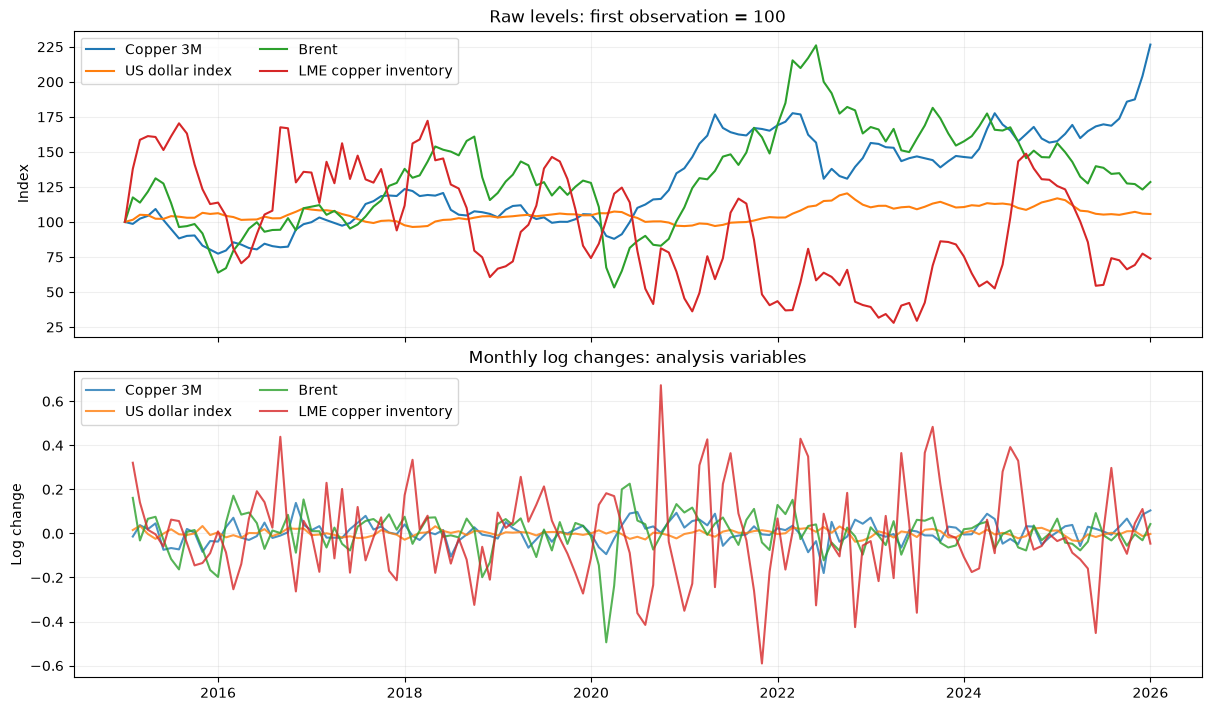

In [5]:
levels = raw.loc[:, list(VARIABLES)]
changes = np.log(levels).diff().iloc[1:]
labels = ["Copper 3M", "US dollar index", "Brent", "LME copper inventory"]
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout="constrained")
for column, label in zip(VARIABLES, labels):
    axes[0].plot(levels.index, levels[column] / levels[column].iloc[0] * 100, label=label)
    axes[1].plot(changes.index, changes[column], label=label, alpha=0.8)
axes[0].set(title="Raw levels: first observation = 100", ylabel="Index")
axes[1].set(title="Monthly log changes: analysis variables", ylabel="Log change")
for ax in axes:
    ax.legend(loc="upper left", ncol=2)
    ax.grid(alpha=0.2)
plt.show()


## 2. 전처리와 진단

양수인 네 시계열에 동일한 로그차분을 적용합니다. 이상값은 표시·검토하고, 자동 winsorization·보간은 하지 않습니다. ADF/KPSS 진단은 변환 후 정상성을 점검하는 보조 자료이며, 검정 하나가 인과적 정상성·선형성·모형 적합성을 입증하지 않습니다.

ParCorr는 조건부 선형 연관에 대한 검정입니다. 비선형성, 구조 변화, 측정오차, 짧은 표본 때문에 관계를 놓치거나 잘못 검출할 수 있습니다. 모델 결과를 보고 유리한 변환을 고르는 탐색은 하지 않습니다.

In [6]:
def preprocess_logdiff(
    frame: pd.DataFrame, variables: Sequence[str] = VARIABLES
) -> pd.DataFrame:
    """Calculate positive-series log differences without filling or clipping."""

    _validate_month_grid(frame, "Preprocessing input")
    variables = list(variables)
    missing = [column for column in variables if column not in frame.columns]
    if missing:
        raise KeyError(f"Required variables are missing: {missing}")
    selected = frame.loc[:, variables].copy()
    if selected.isna().any().any():
        where = selected.isna().sum()
        raise ValueError(f"Internal preprocessing input has missing values: {where[where > 0].to_dict()}")
    nonpositive = (selected <= 0).sum()
    if nonpositive.any():
        raise ValueError(
            "Log differences require strictly positive values: "
            f"{nonpositive[nonpositive > 0].to_dict()}"
        )
    transformed = np.log(selected).diff()
    transformed.attrs = dict(frame.attrs)
    transformed.attrs["transform"] = "monthly natural-log difference"
    return transformed


def stationarity_report(frame: pd.DataFrame) -> pd.DataFrame:
    """Report ADF and KPSS diagnostics; results inform review but never gate discovery."""

    from statsmodels.tsa.stattools import adfuller, kpss

    rows: list[dict[str, Any]] = []
    for column in frame.columns:
        values = frame[column].dropna().to_numpy(dtype=float)
        row: dict[str, Any] = {"variable": column, "n": len(values)}
        messages: list[str] = []
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                adf = adfuller(values, autolag="AIC", result_object=False)
            row.update(adf_stat=float(adf[0]), adf_pvalue=float(adf[1]), adf_lags=int(adf[2]))
            messages.extend(f"ADF: {item.message}" for item in caught)
        except Exception as exc:  # diagnostics should survive short/constant inputs
            row.update(adf_stat=np.nan, adf_pvalue=np.nan, adf_lags=np.nan)
            messages.append(f"ADF failed: {exc}")
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                kpss_result = kpss(values, regression="c", nlags="auto", result_object=False)
            row.update(
                kpss_stat=float(kpss_result[0]),
                kpss_pvalue=float(kpss_result[1]),
                kpss_lags=int(kpss_result[2]),
            )
            messages.extend(f"KPSS: {item.message}" for item in caught)
        except Exception as exc:
            row.update(kpss_stat=np.nan, kpss_pvalue=np.nan, kpss_lags=np.nan)
            messages.append(f"KPSS failed: {exc}")
        adf_stationary = bool(row["adf_pvalue"] < 0.05) if np.isfinite(row["adf_pvalue"]) else False
        kpss_stationary = bool(row["kpss_pvalue"] >= 0.05) if np.isfinite(row["kpss_pvalue"]) else False
        row["diagnostic"] = (
            "both tests support stationarity"
            if adf_stationary and kpss_stationary
            else "mixed or inconclusive; inspect before interpretation"
        )
        row["warnings"] = " | ".join(messages)
        rows.append(row)
    return pd.DataFrame(rows).set_index("variable")




In [7]:
stationarity = stationarity_report(changes)
display(stationarity)
display(Markdown('KPSS의 p=0.1은 표 기반 출력의 상한에 걸린 값입니다. warnings 열의 범위 밖 안내를 함께 읽으세요.'))


,n,adf_stat,adf_pvalue,adf_lags,kpss_stat,kpss_pvalue,kpss_lags,diagnostic,warnings
variable,,,,,,,,,
Com_LME_Cu_3M,132,-3.39220,1.12276e-02,11,0.12567,0.1,3,both tests support stationarity,KPSS: The test statistic is outside of the range of p-values available in the look-up table. The...
Idx_DxyUSD,132,-7.93028,3.52821e-12,0,0.05822,0.1,3,both tests support stationarity,KPSS: The test statistic is outside of the range of p-values available in the look-up table. The...
Com_BrentCrudeOil,132,-7.68811,1.44335e-11,2,0.05010,0.1,1,both tests support stationarity,KPSS: The test statistic is outside of the range of p-values available in the look-up table. The...
Com_LME_Cu_Inv,132,-8.38624,2.43412e-13,1,0.02998,0.1,0,both tests support stationarity,KPSS: The test statistic is outside of the range of p-values available in the look-up table. The...


KPSS의 p=0.1은 표 기반 출력의 상한에 걸린 값입니다. warnings 열의 범위 밖 안내를 함께 읽으세요.

## 3. 사전 지식: 허용 후보와 차단을 분리

현재 네 시장 변수 사이에서 특정 경제 방향이 **불가능**하다고 확정할 근거는 없습니다. 따라서 초기 경제적 차단 목록과 고정 간선 목록은 비어 있습니다. 이는 도메인 검토의 결과이며, 간선을 억지로 막아 그래프를 만들지 않습니다.

시간 역행은 구조적으로 금지합니다. 같은 시점의 서로 다른 변수는 `o?o`, 과거→현재 후보는 자기시차를 포함해 `o?>`로 명시합니다. Tigramite에서 사전 지식에 빠진 링크는 부재로 해석될 수 있어, 전체 허용 후보를 먼저 만든 뒤 근거 있는 차단만 제외합니다. `?`는 이 사전 입력에서 인접성 자체가 미확정이라는 뜻입니다.

예상 부호는 제약으로 강제하지 않습니다. `blocked`·`fixed`·`expected_sign`을 변경할 때에는 변수 정의·자료 출처·이유를 함께 기록해야 합니다.

In [8]:
def _normalise_blocks(
    variables: Sequence[str], tau_max: int, blocks: Iterable[Mapping[str, Any]]
) -> list[dict[str, Any]]:
    names = list(variables)
    normalised: list[dict[str, Any]] = []
    seen: set[tuple[str, str, int]] = set()
    for number, block in enumerate(blocks, start=1):
        required = {"source", "target", "lag", "rationale"}
        absent = required.difference(block)
        if absent:
            raise ValueError(f"Block {number} is missing keys: {sorted(absent)}")
        source, target = str(block["source"]), str(block["target"])
        if source not in names or target not in names:
            raise ValueError(f"Block {number} refers to an unknown variable")
        lag = block["lag"]
        if isinstance(lag, bool) or not isinstance(lag, (int, np.integer)):
            raise TypeError(f"Block {number} lag must be an integer month")
        lag = int(lag)
        if not 0 <= lag <= tau_max:
            raise ValueError(f"Block {number} lag must be between 0 and {tau_max}")
        if lag == 0 and source == target:
            raise ValueError("A contemporaneous self-link is invalid")
        rationale = str(block["rationale"]).strip()
        if not rationale:
            raise ValueError(f"Block {number} requires a non-empty rationale")
        key = (source, target, lag)
        if key in seen:
            raise ValueError(f"Duplicate or contradictory block: {key}")
        seen.add(key)
        normalised.append({"source": source, "target": target, "lag": lag, "rationale": rationale})

    lag_zero = {(b["source"], b["target"]) for b in normalised if b["lag"] == 0}
    for source, target in lag_zero:
        if (target, source) not in lag_zero:
            raise ValueError(
                "Contemporaneous blocks must be symmetric; also block "
                f"{target!r} -> {source!r} at lag 0"
            )
    return normalised


def build_link_assumptions(
    variables: Sequence[str], tau_max: int, blocks: Iterable[Mapping[str, Any]] = ()
) -> dict[int, dict[tuple[int, int], str]]:
    """Build a complete LPCMCI assumptions dictionary.

    Unblocked contemporaneous pairs use ``o?o`` and all lagged candidates use
    ``o?>`` (the future cannot cause the past).  A block is represented by the
    empty string, which means absence in Tigramite.  No macroeconomic links are
    blocked or fixed by default.
    """

    names = list(variables)
    if len(names) != len(set(names)) or not names:
        raise ValueError("variables must be a non-empty sequence of unique names")
    if isinstance(tau_max, bool) or not isinstance(tau_max, (int, np.integer)) or tau_max < 0:
        raise ValueError("tau_max must be a non-negative integer")
    normalised = _normalise_blocks(names, int(tau_max), blocks)
    blocked = {(b["source"], b["target"], b["lag"]) for b in normalised}
    assumptions: dict[int, dict[tuple[int, int], str]] = {j: {} for j in range(len(names))}
    for target_index, target in enumerate(names):
        for source_index, source in enumerate(names):
            if source_index != target_index:
                assumptions[target_index][(source_index, 0)] = (
                    "" if (source, target, 0) in blocked else "o?o"
                )
            for lag in range(1, int(tau_max) + 1):
                assumptions[target_index][(source_index, -lag)] = (
                    "" if (source, target, lag) in blocked else "o?>"
                )
    return assumptions




In [9]:
domain_blocks = []  # 근거가 확인된 실제 차단만 추가. 기본 설정은 비어 있음.
fixed_edges = []
assert not fixed_edges, '이 최소 버전은 fixed edge 입력을 지원하지 않습니다. 근거 확인 후 사전 제약 구현을 확장해야 합니다.'
priors = build_link_assumptions(list(VARIABLES), tau_max=2, blocks=domain_blocks)
display(pd.DataFrame([{
    "source": VARIABLES[i], "target": VARIABLES[j], "lag": -lag, "candidate": mark,
    "status": "allowed_candidate", "expected_sign": "미지정",
} for j, entries in priors.items() for (i, lag), mark in entries.items()]))
display(pd.DataFrame([{
    "documented_domain_blocks": len(domain_blocks), "fixed_edges": len(fixed_edges),
    "temporal_policy": "미래에서 과거로 향하는 원인 후보 금지",
}]))


,source,target,lag,candidate,status,expected_sign
0,Com_LME_Cu_3M,Com_LME_Cu_3M,1,o?>,allowed_candidate,미지정
1,Com_LME_Cu_3M,Com_LME_Cu_3M,2,o?>,allowed_candidate,미지정
2,Idx_DxyUSD,Com_LME_Cu_3M,0,o?o,allowed_candidate,미지정
3,Idx_DxyUSD,Com_LME_Cu_3M,1,o?>,allowed_candidate,미지정
4,Idx_DxyUSD,Com_LME_Cu_3M,2,o?>,allowed_candidate,미지정
5,Com_BrentCrudeOil,Com_LME_Cu_3M,0,o?o,allowed_candidate,미지정
6,Com_BrentCrudeOil,Com_LME_Cu_3M,1,o?>,allowed_candidate,미지정
7,Com_BrentCrudeOil,Com_LME_Cu_3M,2,o?>,allowed_candidate,미지정
8,Com_LME_Cu_Inv,Com_LME_Cu_3M,0,o?o,allowed_candidate,미지정
9,Com_LME_Cu_Inv,Com_LME_Cu_3M,1,o?>,allowed_candidate,미지정


,documented_domain_blocks,fixed_edges,temporal_policy
0,0,0,미래에서 과거로 향하는 원인 후보 금지


## 4. LPCMCI + ParCorr

기본 설정은 시차 0–2개월, `pc_alpha=0.05`, 예비 단계 1회, 비조상 조건집합 크기 상한 3입니다. LPCMCI는 잠재변수를 허용하는 **시계열 PAG/DPAG**를 반환하는 실험적 알고리즘입니다. 여기서 얻은 결과를 완성·검증된 시장 DAG라고 부르지 않습니다.

독립적인 FDR 보장이나 사후 BH 간선 삭제를 적용하지 않습니다. `p_matrix`는 인접성 검사에서 만난 최대 p값, `val_matrix`는 그 검사에 대응한 조건부 부분상관 통계량입니다. **인과효과·방향 신뢰도·사후확률이 아닙니다.**

기본 분석, 초기/후기 96개월, 현물 교체, 최대시차 3, 더 엄격한 alpha=0.01, 재고의 가상 1개월 추가 지연으로 총 7회 분석합니다. 반복 재현 검증을 별도로 1회 수행합니다. 내부 가정이 부적합하면 한계를 보고하며, 관계가 약하다는 이유만으로 다른 알고리즘을 자동 추가하지 않습니다.

In [10]:
def reference_lag(analysis_lag: int, source_delay: int, target_delay: int) -> int:
    """Translate an analysis lag to source/target observation-period lag."""

    return int(analysis_lag) + int(source_delay) - int(target_delay)


def _validate_config(config: RunConfig, variables: Sequence[str]) -> dict[str, int]:
    if config.target not in (TARGET, CASH_TARGET):
        raise ValueError(f"Unsupported target: {config.target}")
    if not config.name.strip():
        raise ValueError("RunConfig.name must not be empty")
    if (
        isinstance(config.tau_max, bool)
        or not isinstance(config.tau_max, (int, np.integer))
        or config.tau_max < 0
    ):
        raise ValueError("tau_max must be a non-negative integer")
    if not 0 < config.pc_alpha < 1:
        raise ValueError("pc_alpha must lie strictly between 0 and 1")
    if config.start is not None and config.end is not None:
        if pd.Timestamp(config.start) > pd.Timestamp(config.end):
            raise ValueError("RunConfig.start must not be later than end")
    unknown = set(config.delays).difference(variables)
    if unknown:
        raise ValueError(f"Delays refer to variables outside this run: {sorted(unknown)}")
    delays: dict[str, int] = {}
    for variable in variables:
        delay = config.delays.get(variable, 0)
        if isinstance(delay, bool) or not isinstance(delay, (int, np.integer)) or delay < 0:
            raise ValueError(f"Delay for {variable} must be a non-negative integer")
        delays[variable] = int(delay)
    return delays


def prepare_data(raw: pd.DataFrame, config: RunConfig) -> tuple[pd.DataFrame, dict[str, Any]]:
    """Slice raw months, log-difference, and apply assumed availability delays."""

    variables = [config.target, *EXPLANATORY]
    delays = _validate_config(config, variables)
    if not isinstance(raw.index, pd.DatetimeIndex):
        raise TypeError("raw must have a DatetimeIndex")
    selected = raw
    if config.start is not None:
        selected = selected.loc[pd.Timestamp(config.start) :]
    if config.end is not None:
        selected = selected.loc[: pd.Timestamp(config.end)]
    if selected.empty:
        raise ValueError(f"Run {config.name!r} selected no raw observations")

    transformed = preprocess_logdiff(selected, variables)
    delayed = pd.DataFrame(index=transformed.index)
    for variable in variables:
        delayed[variable] = transformed[variable].shift(delays[variable])
    complete = delayed.notna().all(axis=1)
    if complete.any():
        first, last = np.flatnonzero(complete.to_numpy())[[0, -1]]
        if not bool(complete.iloc[first : last + 1].all()):
            bad = delayed.index[first : last + 1][~complete.iloc[first : last + 1]].tolist()
            raise ValueError(f"Internal gaps remain after availability alignment: {bad}")
    else:
        raise ValueError("No complete observations remain after transformation and delays")
    frame = delayed.loc[complete].copy()

    dropped = delayed.index[~complete]
    reference_periods = {
        variable: [(date - pd.DateOffset(months=delays[variable])).strftime("%Y-%m") for date in frame.index]
        for variable in variables
    }
    target_reference_dates = reference_periods[config.target]
    metadata: dict[str, Any] = {
        "input_sha256": raw.attrs.get("input_sha256", "unavailable"),
        "source_path": raw.attrs.get("source_path", "unavailable"),
        "ordered_columns": variables,
        "transform": "monthly natural-log difference; no fill or winsorization",
        "availability_status": "assumed delay sensitivity; release dates/vintages unavailable",
        "delays_months": delays,
        "raw_date_bounds": [_iso_month(selected.index.min()), _iso_month(selected.index.max())],
        "raw_n": len(selected),
        "transformed_date_bounds_before_alignment": [
            _iso_month(transformed.index.min()),
            _iso_month(transformed.index.max()),
        ],
        "effective_date_bounds": [_iso_month(frame.index.min()), _iso_month(frame.index.max())],
        "actual_target_dates": target_reference_dates,
        "analysis_availability_dates": [_iso_month(date) for date in frame.index],
        "reference_periods_by_variable": reference_periods,
        "availability_map": {
            variable: {
                "reference_period": "monthly observation represented by the transformed value",
                "assumed_delay_months": delays[variable],
                "analysis_period": "reference period plus assumed delay",
            }
            for variable in variables
        },
        "dropped_boundaries": [_iso_month(date) for date in dropped],
        "boundary_drop_reasons": {
            _iso_month(date): delayed.columns[delayed.loc[date].isna()].tolist() for date in dropped
        },
        "reference_lag_formula": "analysis_lag + delay_source - delay_target",
        "observed_n": len(frame),
    }
    frame.attrs = dict(raw.attrs)
    frame.attrs.update(transform=metadata["transform"], delays_months=delays)
    return frame, metadata


# A readable alias used by the notebook narrative.
prepare_run = prepare_data


def _align_prepared(
    frame: pd.DataFrame, metadata: Mapping[str, Any], common_index: pd.DatetimeIndex
) -> tuple[pd.DataFrame, dict[str, Any]]:
    missing = common_index.difference(frame.index)
    if len(missing):
        raise ValueError(f"Common alignment requests unavailable dates: {missing.tolist()}")
    aligned = frame.loc[common_index].copy()
    updated = dict(metadata)
    removed = frame.index.difference(common_index)
    updated["suite_alignment_drops"] = [_iso_month(date) for date in removed]
    updated["effective_date_bounds"] = [_iso_month(aligned.index.min()), _iso_month(aligned.index.max())]
    updated["analysis_availability_dates"] = [_iso_month(date) for date in aligned.index]
    delays = updated["delays_months"]
    updated["reference_periods_by_variable"] = {
        variable: [(date - pd.DateOffset(months=delays[variable])).strftime("%Y-%m") for date in aligned.index]
        for variable in aligned.columns
    }
    updated["actual_target_dates"] = updated["reference_periods_by_variable"][aligned.columns[0]]
    updated["observed_n"] = len(aligned)
    return aligned, updated




In [11]:
def _frame_sha256(frame: pd.DataFrame) -> str:
    hashed = pd.util.hash_pandas_object(frame, index=True).to_numpy(dtype=np.uint64)
    return sha256(hashed.tobytes() + "\0".join(frame.columns).encode()).hexdigest()


def _result_signature(
    frame: pd.DataFrame, config: RunConfig, metadata: Mapping[str, Any], versions: Mapping[str, str]
) -> str:
    payload = {
        "input_sha256": metadata.get("input_sha256"),
        "prepared_frame_sha256": _frame_sha256(frame),
        "ordered_columns": list(frame.columns),
        "config": _config_dict(config),
        "transform": metadata.get("transform"),
        "delays_months": metadata.get("delays_months"),
        "raw_date_bounds": metadata.get("raw_date_bounds"),
        "effective_date_bounds": metadata.get("effective_date_bounds"),
        "actual_target_dates": metadata.get("actual_target_dates"),
        "package_versions": dict(versions),
        "seed": SEED,
        "algorithm_parameters": metadata.get("algorithm_parameters"),
        "reference_burn": metadata.get("reference_burn"),
        "reference_points": metadata.get("reference_points"),
        "domain_blocks": metadata.get("domain_blocks"),
        "graph_sha256": metadata.get("graph_sha256"),
    }
    canonical = json.dumps(payload, sort_keys=True, separators=(",", ":"), default=_json_value)
    return sha256(canonical.encode()).hexdigest()




In [12]:
def run_model(
    frame: pd.DataFrame,
    config: RunConfig,
    metadata: Mapping[str, Any] | None = None,
    *,
    blocks: Iterable[Mapping[str, Any]] = (),
) -> RunResult:
    """Run LPCMCI+ParCorr on an already prepared, complete monthly frame."""

    from tigramite import data_processing as pp
    from tigramite.independence_tests.parcorr import ParCorr
    from tigramite.lpcmci import LPCMCI

    variables = [config.target, *EXPLANATORY]
    _validate_config(config, variables)
    _validate_month_grid(frame, "Prepared discovery frame")
    if list(frame.columns) != variables:
        raise ValueError(f"Prepared columns must be ordered as {variables}")
    if frame.isna().any().any() or not np.isfinite(frame.to_numpy(dtype=float)).all():
        raise ValueError("Prepared discovery frame must contain only finite values")
    reference_burn = max(REFERENCE_BURN, 2 * int(config.tau_max))
    if len(frame) <= reference_burn:
        raise ValueError(f"At least {reference_burn + 1} prepared observations are required")

    run_metadata = dict(metadata or {})
    run_metadata.setdefault("input_sha256", "unavailable")
    run_metadata.setdefault("ordered_columns", variables)
    run_metadata.setdefault("transform", "caller-prepared")
    run_metadata.setdefault("delays_months", {variable: 0 for variable in variables})
    run_metadata.setdefault("raw_date_bounds", [_iso_month(frame.index.min()), _iso_month(frame.index.max())])
    run_metadata.setdefault("effective_date_bounds", [_iso_month(frame.index.min()), _iso_month(frame.index.max())])
    run_metadata.setdefault("actual_target_dates", [_iso_month(date) for date in frame.index])
    run_metadata["observed_n"] = len(frame)
    reference_points = np.arange(reference_burn, len(frame), dtype=int)
    run_metadata["reference_points"] = reference_points.tolist()
    run_metadata["reference_point_dates"] = [_iso_month(frame.index[i]) for i in reference_points]
    actual_target_dates = run_metadata["actual_target_dates"]
    run_metadata["reference_point_target_dates"] = [actual_target_dates[i] for i in reference_points]
    run_metadata["effective_n"] = len(reference_points)
    run_metadata["reference_burn"] = reference_burn
    run_metadata["ci_cutoff_note"] = (
        "Tigramite reference points begin after a common six-month burn; individual CI tests may use "
        "different conditioning-set sample constructions."
    )
    normalised_blocks = _normalise_blocks(variables, config.tau_max, blocks)
    run_metadata["domain_blocks"] = normalised_blocks
    run_metadata["algorithm_parameters"] = {
        "method": "LPCMCI",
        "conditional_independence_test": "ParCorr",
        "significance": "analytic",
        "tau_min": 0,
        "tau_max": int(config.tau_max),
        "pc_alpha": float(config.pc_alpha),
        "n_preliminary_iterations": 1,
        "max_p_non_ancestral": 3,
        "fdr_correction": None,
    }
    run_metadata["statistics_note"] = (
        "p_matrix is the maximum CI p-value encountered; val_matrix is its associated ParCorr statistic. "
        "They are not effect sizes, direction confidence, or posterior probabilities; no FDR pruning applied."
    )
    versions = _package_versions()
    run_metadata["package_versions"] = versions
    run_metadata["seed"] = SEED

    values = frame.to_numpy(dtype=float, copy=True)
    dataframe = pp.DataFrame(
        values,
        var_names=variables,
        datatime=frame.index.to_numpy(copy=True),
        reference_points=reference_points.copy(),
    )
    assumptions = build_link_assumptions(variables, config.tau_max, normalised_blocks)
    started = time.perf_counter()
    model = LPCMCI(dataframe=dataframe, cond_ind_test=ParCorr(seed=SEED), verbosity=0)
    output = model.run_lpcmci(
        link_assumptions=assumptions,
        tau_min=0,
        tau_max=config.tau_max,
        pc_alpha=config.pc_alpha,
        n_preliminary_iterations=1,
        max_p_non_ancestral=3,
    )
    run_metadata["elapsed_seconds"] = time.perf_counter() - started
    graph = np.array(output["graph"], copy=True)
    graph_bytes = graph.astype("U3", copy=False).tobytes()
    run_metadata["graph_sha256"] = sha256(
        str(graph.shape).encode() + str(graph.dtype).encode() + graph_bytes
    ).hexdigest()
    signature = _result_signature(frame, config, run_metadata, versions)
    return RunResult(
        name=config.name,
        target=config.target,
        variables=variables.copy(),
        config=_config_dict(config),
        frame=frame.copy(deep=True),
        graph=graph,
        val_matrix=np.array(output["val_matrix"], dtype=float, copy=True),
        p_matrix=np.array(output["p_matrix"], dtype=float, copy=True),
        signature=signature,
        metadata=run_metadata,
    )


run_discovery = run_model


def rerun_result(result: RunResult) -> RunResult:
    """Replay a result on defensive copies of its exact frame and settings."""

    config_data = dict(result.config)
    config_data["delays"] = dict(config_data.get("delays", {}))
    config = RunConfig(**config_data)
    metadata = dict(result.metadata)
    blocks = metadata.get("domain_blocks", ())
    return run_model(result.frame.copy(deep=True), config, metadata, blocks=blocks)




In [13]:
def suite_configs() -> list[RunConfig]:
    """Return the seven agreed baseline and sensitivity configurations."""

    return [
        RunConfig(name="baseline"),
        RunConfig(name="early_window", start="2015-01-01", end="2022-12-01"),
        RunConfig(name="recent_window", start="2018-02-01", end="2026-01-01"),
        RunConfig(name="cash_target", target=CASH_TARGET),
        RunConfig(name="lag3", tau_max=3),
        RunConfig(name="alpha_001", pc_alpha=0.01),
        RunConfig(name="inventory_delay_1m", delays={"Com_LME_Cu_Inv": 1}),
    ]


def run_suite(
    csv_path: str | Path, blocks: Iterable[Mapping[str, Any]] = ()
) -> dict[str, RunResult]:
    """Run all seven configurations with comparable full-period samples."""

    raw = load_data(csv_path)
    configs = suite_configs()
    domain_blocks = [dict(block) for block in blocks]
    prepared: dict[str, tuple[pd.DataFrame, dict[str, Any]]] = {
        config.name: prepare_data(raw, config) for config in configs
    }
    full_period_names = ("baseline", "cash_target", "lag3", "alpha_001", "inventory_delay_1m")
    common_index = prepared[full_period_names[0]][0].index
    for name in full_period_names[1:]:
        common_index = common_index.intersection(prepared[name][0].index, sort=False)
    if common_index.empty:
        raise ValueError("Full-period sensitivity configurations have no common transformed dates")
    for name in full_period_names:
        prepared[name] = _align_prepared(*prepared[name], common_index)

    results: dict[str, RunResult] = {}
    for config in configs:
        frame, metadata = prepared[config.name]
        config_blocks = domain_blocks
        if config.target == CASH_TARGET:
            config_blocks = [
                {
                    **block,
                    "source": CASH_TARGET if block.get("source") == TARGET else block.get("source"),
                    "target": CASH_TARGET if block.get("target") == TARGET else block.get("target"),
                }
                for block in domain_blocks
            ]
        results[config.name] = run_model(frame, config, metadata, blocks=config_blocks)
    return results


def result_summary(result: RunResult) -> pd.DataFrame:
    """Return present, non-empty graph entries as a novice-readable table."""

    rows: list[dict[str, Any]] = []
    graph = np.asarray(result.graph)
    for source_index, source in enumerate(result.variables):
        for target_index, target in enumerate(result.variables):
            for lag in range(graph.shape[2]):
                mark = str(graph[source_index, target_index, lag])
                if not mark:
                    continue
                source_delay = result.metadata["delays_months"].get(source, 0)
                target_delay = result.metadata["delays_months"].get(target, 0)
                rows.append(
                    {
                        "source": source,
                        "target": target,
                        "analysis_lag": lag,
                        "reference_lag": reference_lag(lag, source_delay, target_delay),
                        "edge_mark": mark,
                        "parcorr_stat": float(result.val_matrix[source_index, target_index, lag]),
                        "max_ci_pvalue": float(result.p_matrix[source_index, target_index, lag]),
                    }
                )
    columns = [
        "source",
        "target",
        "analysis_lag",
        "reference_lag",
        "edge_mark",
        "parcorr_stat",
        "max_ci_pvalue",
    ]
    return pd.DataFrame(rows, columns=columns)


In [14]:
results = run_suite(DATA_PATH, blocks=domain_blocks)
baseline = results["baseline"]
run_overview = pd.DataFrame([{
    "run": name, "target": r.target,
    "raw_months": r.metadata["raw_n"],
    "aligned_months": r.metadata["observed_n"],
    "CI_reference_months": r.metadata["effective_n"],
    "first_CI_month": r.metadata["reference_point_dates"][0],
    "last_CI_month": r.metadata["reference_point_dates"][-1],
    "max_lag": r.config["tau_max"], "alpha": r.config["pc_alpha"],
    "extra_delay": str(r.config["delays"]),
    "boundary_drops": ", ".join(r.metadata["dropped_boundaries"]
                                + r.metadata.get("suite_alignment_drops", [])),
    "elapsed_seconds": r.metadata["elapsed_seconds"],
    "signature": r.signature[:12],
} for name, r in results.items()])
display(run_overview)
paired = ["baseline", "cash_target", "lag3", "alpha_001", "inventory_delay_1m"]
assert all(results[name].metadata["reference_point_dates"] ==
           baseline.metadata["reference_point_dates"] for name in paired)
display(Markdown(
    f"**기본 실행 서명:** `{baseline.signature}`  "
    "\n원본·변수·표본 날짜·변환·지연·알고리즘 설정·원래 PAG·패키지 버전을 함께 고정합니다."
))


,run,target,raw_months,aligned_months,CI_reference_months,first_CI_month,last_CI_month,max_lag,alpha,extra_delay,boundary_drops,elapsed_seconds,signature
0,baseline,Com_LME_Cu_3M,133,131,125,2015-09,2026-01,2,0.05,{},"2015-01, 2015-02",0.83724,ae45ce0851fe
1,early_window,Com_LME_Cu_3M,96,95,89,2015-08,2022-12,2,0.05,{},2015-01,0.51071,fe0fe2d40a47
2,recent_window,Com_LME_Cu_3M,96,95,89,2018-09,2026-01,2,0.05,{},2018-02,0.55895,0c05bdb15a82
3,cash_target,Com_LME_Cu_Cash,133,131,125,2015-09,2026-01,2,0.05,{},"2015-01, 2015-02",0.88167,15ebd3cd1a41
4,lag3,Com_LME_Cu_3M,133,131,125,2015-09,2026-01,3,0.05,{},"2015-01, 2015-02",1.36105,a6bada7df3b9
5,alpha_001,Com_LME_Cu_3M,133,131,125,2015-09,2026-01,2,0.01,{},"2015-01, 2015-02",0.51391,001388073381
6,inventory_delay_1m,Com_LME_Cu_3M,133,131,125,2015-09,2026-01,2,0.05,{'Com_LME_Cu_Inv': 1},"2015-01, 2015-02",0.77429,c903f2b3d127


**기본 실행 서명:** `ae45ce0851fe80251f031ffe1354b8ab411f1725d8084d1c6e6e101e0f2ba222`  
원본·변수·표본 날짜·변환·지연·알고리즘 설정·원래 PAG·패키지 버전을 함께 고정합니다.

## 5. 원래 PAG와 구리 가격의 상류 경로

간선 표의 source/target은 저장된 왼쪽/오른쪽 변수입니다. 실제 방향은 mark를 읽어야 합니다. 예를 들어 Copper <-o DXY는 DXY 쪽이 미확정인 연결입니다. 경로 표는 이 표기를 해석한 진행 방향으로 정렬합니다.

| 표기 | 이 Notebook에서의 의미 |
|---|---|
| `A --> B` | A가 B의 조상이라는 방향 정보. 숨은 매개를 포함할 수 있어 직접 효과와 동일하지 않음 |
| `A o-> B` | A 쪽 조상성이 미확정. 직접 방향과 잠재교란 가능성을 구분해야 함 |
| `A o-o B` | 양쪽 끝점이 미확정 |
| `A <-> B` | 잠재교란과 양립하는 연결. 양방향 효과 또는 방향 미정으로 바꾸어 해석하지 않음 |
| 기타·충돌 표기 | 분류되지 않은 상태로 남기며 방향 경로에 사용하지 않음 |

시간을 펼친 그래프에서 최근 6개월·최대 3개 간선 길이의 경로를 탐색합니다. `definite`는 확정 방향만 따르는 경로, `possible`은 미확정 끝점을 포함하는 방향 호환 후보입니다. 후보 경로는 하나의 참 DAG에서 실제 실현 가능함이 보증된 경로가 아닙니다. `<->`는 원인 방향 경로에서 제외합니다.

,source,target,lag,mark,edge_class,statistic,p_value,edge_key
0,Com_LME_Cu_3M,Idx_DxyUSD,0,<-o,partially_directed,-0.27544,0.00205,tau0:Com_LME_Cu_3M|Idx_DxyUSD
1,Com_LME_Cu_3M,Com_BrentCrudeOil,0,<--,directed,0.35333,0.00006,tau0:Com_LME_Cu_3M|Com_BrentCrudeOil
2,Com_LME_Cu_3M,Com_LME_Cu_Inv,0,<-o,partially_directed,-0.21326,0.01787,tau0:Com_LME_Cu_3M|Com_LME_Cu_Inv
3,Idx_DxyUSD,Idx_DxyUSD,1,o->,partially_directed,0.33074,0.00018,lag1:Idx_DxyUSD->Idx_DxyUSD
4,Com_BrentCrudeOil,Com_BrentCrudeOil,1,<->,latent_compatible,0.23476,0.00868,lag1:Com_BrentCrudeOil->Com_BrentCrudeOil
5,Com_LME_Cu_Inv,Com_LME_Cu_Inv,1,o->,partially_directed,0.18284,0.04210,lag1:Com_LME_Cu_Inv->Com_LME_Cu_Inv


Retained adjacencies: 6


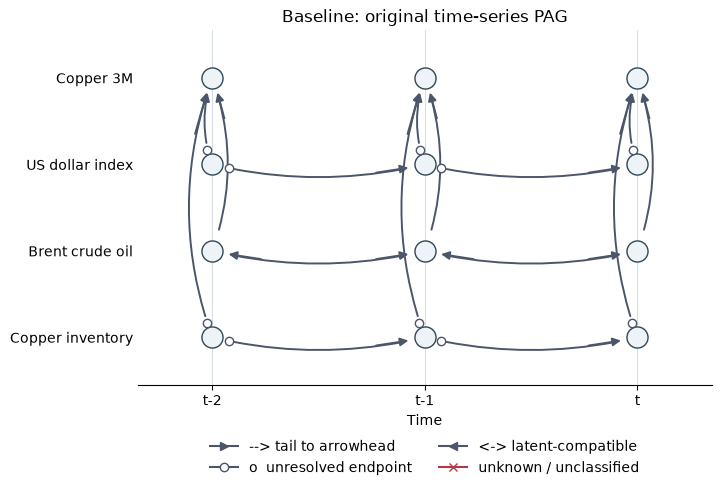

Bounded target upstream routes: 7


,source,target,edge_count,total_lag,max_edge_lag,path_type,path,timestamps,edge_keys,path_key
0,Com_BrentCrudeOil,Com_LME_Cu_3M,1,0,0,definite,Com_BrentCrudeOil(t+0) -> Com_LME_Cu_3M(t+0),"(0, 0)","(tau0:Com_LME_Cu_3M|Com_BrentCrudeOil,)",Com_BrentCrudeOil(t+0)@0|Com_LME_Cu_3M(t+0)@0|edge:tau0:Com_LME_Cu_3M|Com_BrentCrudeOil:<--|clas...
1,Com_LME_Cu_Inv,Com_LME_Cu_3M,1,0,0,possible,Com_LME_Cu_Inv(t+0) -> Com_LME_Cu_3M(t+0),"(0, 0)","(tau0:Com_LME_Cu_3M|Com_LME_Cu_Inv,)",Com_LME_Cu_Inv(t+0)@0|Com_LME_Cu_3M(t+0)@0|edge:tau0:Com_LME_Cu_3M|Com_LME_Cu_Inv:<-o|class:poss...
2,Idx_DxyUSD,Com_LME_Cu_3M,1,0,0,possible,Idx_DxyUSD(t+0) -> Com_LME_Cu_3M(t+0),"(0, 0)","(tau0:Com_LME_Cu_3M|Idx_DxyUSD,)",Idx_DxyUSD(t+0)@0|Com_LME_Cu_3M(t+0)@0|edge:tau0:Com_LME_Cu_3M|Idx_DxyUSD:<-o|class:possible
3,Com_LME_Cu_Inv,Com_LME_Cu_3M,2,1,1,possible,Com_LME_Cu_Inv(t-1) -> Com_LME_Cu_Inv(t+0) -> Com_LME_Cu_3M(t+0),"(-1, 0, 0)","(lag1:Com_LME_Cu_Inv->Com_LME_Cu_Inv, tau0:Com_LME_Cu_3M|Com_LME_Cu_Inv)",Com_LME_Cu_Inv(t-1)@-1|Com_LME_Cu_Inv(t+0)@0|Com_LME_Cu_3M(t+0)@0|edge:lag1:Com_LME_Cu_Inv->Com_...
4,Idx_DxyUSD,Com_LME_Cu_3M,2,1,1,possible,Idx_DxyUSD(t-1) -> Idx_DxyUSD(t+0) -> Com_LME_Cu_3M(t+0),"(-1, 0, 0)","(lag1:Idx_DxyUSD->Idx_DxyUSD, tau0:Com_LME_Cu_3M|Idx_DxyUSD)",Idx_DxyUSD(t-1)@-1|Idx_DxyUSD(t+0)@0|Com_LME_Cu_3M(t+0)@0|edge:lag1:Idx_DxyUSD->Idx_DxyUSD:o->|e...
5,Com_LME_Cu_Inv,Com_LME_Cu_3M,3,2,1,possible,Com_LME_Cu_Inv(t-2) -> Com_LME_Cu_Inv(t-1) -> Com_LME_Cu_Inv(t+0) -> Com_LME_Cu_3M(t+0),"(-2, -1, 0, 0)","(lag1:Com_LME_Cu_Inv->Com_LME_Cu_Inv, lag1:Com_LME_Cu_Inv->Com_LME_Cu_Inv, tau0:Com_LME_Cu_3M|Co...",Com_LME_Cu_Inv(t-2)@-2|Com_LME_Cu_Inv(t-1)@-1|Com_LME_Cu_Inv(t+0)@0|Com_LME_Cu_3M(t+0)@0|edge:la...
6,Idx_DxyUSD,Com_LME_Cu_3M,3,2,1,possible,Idx_DxyUSD(t-2) -> Idx_DxyUSD(t-1) -> Idx_DxyUSD(t+0) -> Com_LME_Cu_3M(t+0),"(-2, -1, 0, 0)","(lag1:Idx_DxyUSD->Idx_DxyUSD, lag1:Idx_DxyUSD->Idx_DxyUSD, tau0:Com_LME_Cu_3M|Idx_DxyUSD)",Idx_DxyUSD(t-2)@-2|Idx_DxyUSD(t-1)@-1|Idx_DxyUSD(t+0)@0|Com_LME_Cu_3M(t+0)@0|edge:lag1:Idx_DxyUS...


In [15]:
baseline_edges = edge_table(
    baseline.graph, baseline.variables, baseline.val_matrix, baseline.p_matrix,
)
display(baseline_edges)
print("Retained adjacencies:", len(baseline_edges))
plot_pag(baseline.graph, baseline.variables, title="Baseline: original time-series PAG")
plt.show()
baseline_paths = upstream_paths(baseline.graph, baseline.variables, baseline.target)
print("Bounded target upstream routes:", len(baseline_paths))
display(baseline_paths.head(40))


## 6. 설정별 안정성

초기 96개월(2015-01–2022-12)과 후기 96개월(2018-02–2026-01)은 겹치는 구간이 있어 독립적인 재현 실험이 아닙니다. 현물 교체에서는 가격 변수의 역할을 `TARGET`으로 맞춥니다. 기본·현물·시차·alpha·가상 지연 분석은 비교 가능한 표본 날짜를 정렬하고, 실제 유효 표본 수와 버려진 경계 월을 기록합니다.

정확한 변수쌍·시차·끝점 표기의 재등장을 집계합니다. 시차 3 간선에 최대시차 2 실행을 실패 사례로 포함하지 않습니다. 재등장 횟수와 조건부 연관 부호의 일관성은 기술적 안정성 지표이며, 인과적 신뢰확률이나 통과 점수가 아닙니다.

In [16]:
def canonical(text, result):
    return str(text).replace(result.target, "TARGET")

ordinary = {name: r for name, r in results.items()
            if not any(r.config.get("delays", {}).values())}
edge_sets, sign_sets, path_sets, path_lags = {}, {}, {}, {}
for name, result in ordinary.items():
    table = edge_table(result.graph, result.variables, result.val_matrix, result.p_matrix)
    records = {}
    for row in table.itertuples():
        key = (canonical(row.source, result), canonical(row.target, result), row.lag, row.mark)
        records[key] = row.statistic
    edge_sets[name] = set(records)
    sign_sets[name] = records
    paths = upstream_paths(result.graph, result.variables, result.target)
    path_sets[name] = {canonical(k, result) for k in paths.path_key}
    for row in paths.itertuples():
        path_lags[canonical(row.path_key, result)] = row.max_edge_lag

support_rows = []
for key in sorted(set().union(*edge_sets.values())):
    eligible = [name for name, r in ordinary.items() if r.config["tau_max"] >= key[2]]
    present = [name for name in eligible if key in edge_sets[name]]
    signs = sorted({
        int(np.sign(sign_sets[name][key])) for name in present
        if np.isfinite(sign_sets[name][key])
    })
    support_rows.append(dict(source=key[0], target=key[1], lag=key[2], mark=key[3],
        recurrence=f"{len(present)}/{len(eligible)}", runs=", ".join(present),
        conditional_statistic_signs=str(signs)))
edge_stability = pd.DataFrame(support_rows)
display(edge_stability)

path_rows = []
for key, max_lag in sorted(path_lags.items()):
    eligible = [name for name, r in ordinary.items() if r.config["tau_max"] >= max_lag]
    present = [name for name in eligible if key in path_sets[name]]
    path_rows.append(dict(path=key, recurrence=f"{len(present)}/{len(eligible)}",
                          runs=", ".join(present)))
path_stability = pd.DataFrame(path_rows)
display(path_stability.head(40))

# 연결 반복과 끝점 방향 반복은 별도로 요약합니다.
target_summary = []
for variable in baseline.variables[1:]:
    matching = {
        name: [key for key in keys
               if key[2] == 0 and {key[0], key[1]} == {"TARGET", variable}]
        for name, keys in edge_sets.items()
    }
    present = [name for name, keys in matching.items() if keys]
    patterns = {}
    for keys in matching.values():
        for key in keys:
            patterns[key[3]] = patterns.get(key[3], 0) + 1
    target_summary.append({
        "pair": f"TARGET / {variable}", "lag": 0,
        "adjacency_recurrence": f"{len(present)}/{len(ordinary)}",
        "endpoint_patterns_TARGET_on_left": str(patterns),
    })
display(pd.DataFrame(target_summary))
display(Markdown(
    "연결 반복과 방향 안정성은 별개입니다. 상단의 정확한 재등장 횟수와 "
    "끝점 표기를 함께 읽고, 독립적 반복 횟수나 신뢰확률로 해석하지 않습니다."
))
print("Cash replacement gives identical baseline graph:",
      np.array_equal(baseline.graph, results["cash_target"].graph))


,source,target,lag,mark,recurrence,runs,conditional_statistic_signs
0,Com_BrentCrudeOil,Com_BrentCrudeOil,1,-->,1/6,early_window,[1]
1,Com_BrentCrudeOil,Com_BrentCrudeOil,1,<->,5/6,"baseline, recent_window, cash_target, lag3, alpha_001",[1]
2,Com_BrentCrudeOil,Com_BrentCrudeOil,3,o->,1/1,lag3,[-1]
3,Com_LME_Cu_Inv,Com_LME_Cu_Inv,1,o->,4/6,"baseline, recent_window, cash_target, lag3",[1]
4,Idx_DxyUSD,Idx_DxyUSD,1,o->,6/6,"baseline, early_window, recent_window, cash_target, lag3, alpha_001",[1]
5,TARGET,Com_BrentCrudeOil,0,<--,4/6,"baseline, early_window, cash_target, lag3",[1]
6,TARGET,Com_BrentCrudeOil,0,<->,1/6,recent_window,[1]
7,TARGET,Com_BrentCrudeOil,0,o->,1/6,alpha_001,[1]
8,TARGET,Com_BrentCrudeOil,1,<->,1/6,early_window,[1]
9,TARGET,Com_LME_Cu_Inv,0,<-o,3/6,"baseline, cash_target, lag3",[-1]


,path,recurrence,runs
0,Com_BrentCrudeOil(t+0)@0|TARGET(t+0)@0|edge:tau0:TARGET|Com_BrentCrudeOil:<--|class:definite,4/6,"baseline, early_window, cash_target, lag3"
1,Com_BrentCrudeOil(t-1)@-1|Com_BrentCrudeOil(t+0)@0|TARGET(t+0)@0|edge:lag1:Com_BrentCrudeOil->Co...,1/6,early_window
2,Com_BrentCrudeOil(t-2)@-2|Com_BrentCrudeOil(t-1)@-1|Com_BrentCrudeOil(t+0)@0|TARGET(t+0)@0|edge:...,1/6,early_window
3,Com_BrentCrudeOil(t-3)@-3|Com_BrentCrudeOil(t+0)@0|TARGET(t+0)@0|edge:lag3:Com_BrentCrudeOil->Co...,1/1,lag3
4,Com_BrentCrudeOil(t-6)@-6|Com_BrentCrudeOil(t-3)@-3|Com_BrentCrudeOil(t+0)@0|TARGET(t+0)@0|edge:...,1/1,lag3
5,Com_LME_Cu_Inv(t+0)@0|TARGET(t+0)@0|edge:tau0:TARGET|Com_LME_Cu_Inv:<-o|class:possible,3/6,"baseline, cash_target, lag3"
6,Com_LME_Cu_Inv(t-1)@-1|Com_LME_Cu_Inv(t+0)@0|TARGET(t+0)@0|edge:lag1:Com_LME_Cu_Inv->Com_LME_Cu_...,3/6,"baseline, cash_target, lag3"
7,Com_LME_Cu_Inv(t-2)@-2|Com_LME_Cu_Inv(t-1)@-1|Com_LME_Cu_Inv(t+0)@0|TARGET(t+0)@0|edge:lag1:Com_...,3/6,"baseline, cash_target, lag3"
8,Idx_DxyUSD(t+0)@0|TARGET(t+0)@0|edge:tau0:TARGET|Idx_DxyUSD:<--|class:definite,1/6,recent_window
9,Idx_DxyUSD(t+0)@0|TARGET(t+0)@0|edge:tau0:TARGET|Idx_DxyUSD:<-o|class:possible,4/6,"baseline, early_window, cash_target, lag3"


,pair,lag,adjacency_recurrence,endpoint_patterns_TARGET_on_left
0,TARGET / Idx_DxyUSD,0,6/6,"{'<-o': 4, '<--': 1, 'o-o': 1}"
1,TARGET / Com_BrentCrudeOil,0,6/6,"{'<--': 4, '<->': 1, 'o->': 1}"
2,TARGET / Com_LME_Cu_Inv,0,3/6,{'<-o': 3}


연결 반복과 방향 안정성은 별개입니다. 상단의 정확한 재등장 횟수와 끝점 표기를 함께 읽고, 독립적 반복 횟수나 신뢰확률로 해석하지 않습니다.

Cash replacement gives identical baseline graph: True


## 7. 정보시점: 실제 입수시점 검증과 가정 실험의 구분

CSV의 날짜는 관측월 라벨로만 사용합니다. 현재 자료만으로 당시 이용 가능했던 빈티지와 발표일을 복원할 수 없습니다. **이 절은 실제 point-in-time 검증이 아니라, 재고 정보를 1개월 더 늦게 받았다고 가정한 민감도 분석입니다.**

`availability = reference + delay`라는 가정 아래,
`reference_lag = analysis_lag + delay_source - delay_target`로 대응 관계를 기록합니다.
입수시점 축에서의 lag와 경제적 관측월 축의 lag를 한 표기의 ‘선행성’으로 섞지 않습니다. 이 가정은 실제 LME 발표 지연이 1개월이라는 주장이 아닙니다.

In [17]:
timing_rows = []
for name, result in results.items():
    if name != "baseline" and not any(result.config.get("delays", {}).values()):
        continue
    delays = result.config.get("delays", {})
    table = edge_table(result.graph, result.variables, result.val_matrix, result.p_matrix)
    for row in table.itertuples():
        timing_rows.append(dict(
            run=name, source=row.source, target=row.target, mark=row.mark,
            lag_analysis=row.lag,
            lag_reference=row.lag + delays.get(row.source, 0) - delays.get(row.target, 0),
            interpretation="보유 자료의 관측월 축" if name == "baseline" else "추가 지연 가정",
        ))
display(pd.DataFrame(timing_rows))


,run,source,target,mark,lag_analysis,lag_reference,interpretation
0,baseline,Com_LME_Cu_3M,Idx_DxyUSD,<-o,0,0,보유 자료의 관측월 축
1,baseline,Com_LME_Cu_3M,Com_BrentCrudeOil,<--,0,0,보유 자료의 관측월 축
2,baseline,Com_LME_Cu_3M,Com_LME_Cu_Inv,<-o,0,0,보유 자료의 관측월 축
3,baseline,Idx_DxyUSD,Idx_DxyUSD,o->,1,1,보유 자료의 관측월 축
4,baseline,Com_BrentCrudeOil,Com_BrentCrudeOil,<->,1,1,보유 자료의 관측월 축
5,baseline,Com_LME_Cu_Inv,Com_LME_Cu_Inv,o->,1,1,보유 자료의 관측월 축
6,inventory_delay_1m,Com_LME_Cu_3M,Idx_DxyUSD,<-o,0,0,추가 지연 가정
7,inventory_delay_1m,Com_LME_Cu_3M,Com_BrentCrudeOil,<--,0,0,추가 지연 가정
8,inventory_delay_1m,Com_LME_Cu_3M,Com_LME_Cu_Inv,-->,1,0,추가 지연 가정
9,inventory_delay_1m,Idx_DxyUSD,Idx_DxyUSD,o->,1,1,추가 지연 가정


## 8. Codex의 실제 결과 검토

아래 판단은 이 실행 결과를 읽은 Codex의 도메인 검토입니다. 별도 GPT 전달 문서와 자동 API 호출은 사용하지 않습니다. 원래 PAG는 변경하지 않고, 허용되는 미확정 끝점의 보완만 별도 그래프에 적용합니다.

추가 방향은 외부 가정으로 표시합니다. 확정 화살촉·잠재교란 연결·부재를 덮어쓰지 않고 시간·기본 조상성 모순을 검사하지만, 이 검사만으로 완전한 PAG 동치류 적합성이 인증되는 것은 아닙니다. 근거가 부족하거나 충돌하는 관계는 미확정으로 남깁니다. 입력·설정이 달라지면 기존 검토를 자동 재사용하지 않습니다.

In [18]:
# Codex가 이 서명의 실제 결과와 아래 문헌을 검토한 기록.
# 원본의 circle을 확정 데이터 결과로 바꾸는 것이 아니라 작업모형의 가정을 추가합니다.
CODEX_REVIEW_SIGNATURE = "ae45ce0851fe80251f031ffe1354b8ab411f1725d8084d1c6e6e101e0f2ba222"
IMF_MONETARY = "https://www.imf.org/-/media/files/publications/wp/2023/english/wpiea2023215-print-pdf.pdf"
BIS_DOLLAR = "https://www.bis.org/publications/working-paper-1083-commodity-prices-and-us-dollar"
IMF_METALS_OIL = "https://www.imf.org/en/blogs/articles/2015/09/14/metals-and-oil-a-tale-of-two-commodities"
CODEX_ORIENTATIONS = [{
    "signature": CODEX_REVIEW_SIGNATURE,
    "source": "Idx_DxyUSD", "target": TARGET, "lag": 0,
    "original_mark": "o->", "proposed_mark": "-->",
    "rationale": (
        "H1 — 추가 식별 가정: 작업모형에서는 달러의 가격표시·해외 수요·금융 경로를 "
        "근거로 같은 달 DXY 변화가 구리 가격 변화의 조상이라고 가정한다. "
        "IMF WP23/215의 경로 설명과 부합하지만 이 자료에서 식별된 방향은 아니다."
    ),
    "counterargument": (
        "미국 통화정책·세계 수요·위험선호가 두 변수를 함께 움직였을 수 있다. "
        "월간 집계는 월내 순서를 확인하지 못하며 BIS 연구처럼 관계의 부호도 "
        "상황에 따라 달라질 수 있다. 순수한 잠재공통원인 설명을 배제한 것은 아니다."
    ),
    "sources": [IMF_MONETARY, BIS_DOLLAR],
    "disposition": "accepted",
}]
CODEX_ASSESSMENTS = [
    {
        "relation": "DXY o-> Copper 3M (lag 0)",
        "decision": "작업가설 H1에서만 DXY --> Copper로 보완",
        "interpretation": "음의 조건부 연관은 달러 표시가격·수요 경로와 부합",
        "counterargument": "누락된 정책·수요 충격 및 월내 순서의 불확실성",
        "evidence_status": "문헌을 참고한 외부 가정; 데이터 식별과 구분",
        "sources": [IMF_MONETARY, BIS_DOLLAR],
    },
    {
        "relation": "LME inventory o-> Copper 3M (lag 0)",
        "decision": "circle 유지",
        "interpretation": "재고·가격의 음의 연관은 수급 설명 후보",
        "counterargument": "재고는 수요·기대·보유비용에도 반응하여 공통원인 설명이 가능",
        "evidence_status": "단일 원인 방향으로 확정하지 않음",
        "sources": [IMF_MONETARY],
    },
    {
        "relation": "Brent --> Copper 3M (lag 0)",
        "decision": "발견된 방향을 보존",
        "interpretation": "양의 연관에는 채굴·정련 비용 및 공통 원자재 경기 경로가 가능",
        "counterargument": "월내 시간순서·독립적 에너지 비용 효과는 확인되지 않음",
        "evidence_status": "PAG의 방향 정보; 직접 인과효과 추정 아님",
        "sources": [IMF_METALS_OIL],
    },
    {
        "relation": "Brent(t-1) <-> Brent(t)",
        "decision": "잠재교란 호환 표기를 보존",
        "interpretation": "지속되는 누락 충격 등과 양립하는 연속 월 연결",
        "counterargument": "실제 잠재변수의 존재·정체가 입증된 것은 아님",
        "evidence_status": "양방향 효과나 미정 방향으로 변환하지 않음",
        "sources": [],
    },
    {
        "relation": "DXY / inventory: lag-1 self o->",
        "decision": "자기시차의 circle 유지",
        "interpretation": "자기계열의 시차 연관",
        "counterargument": "지속되는 공통 요인·측정 구조를 배제하지 못함",
        "evidence_status": "자기시차 연관만으로 시장 구조를 확정하지 않음",
        "sources": [],
    },
]


,relation,decision,interpretation,counterargument,evidence_status,sources
0,DXY o-> Copper 3M (lag 0),작업가설 H1에서만 DXY --> Copper로 보완,음의 조건부 연관은 달러 표시가격·수요 경로와 부합,누락된 정책·수요 충격 및 월내 순서의 불확실성,문헌을 참고한 외부 가정; 데이터 식별과 구분,"[https://www.imf.org/-/media/files/publications/wp/2023/english/wpiea2023215-print-pdf.pdf, http..."
1,LME inventory o-> Copper 3M (lag 0),circle 유지,재고·가격의 음의 연관은 수급 설명 후보,재고는 수요·기대·보유비용에도 반응하여 공통원인 설명이 가능,단일 원인 방향으로 확정하지 않음,[https://www.imf.org/-/media/files/publications/wp/2023/english/wpiea2023215-print-pdf.pdf]
2,Brent --> Copper 3M (lag 0),발견된 방향을 보존,양의 연관에는 채굴·정련 비용 및 공통 원자재 경기 경로가 가능,월내 시간순서·독립적 에너지 비용 효과는 확인되지 않음,PAG의 방향 정보; 직접 인과효과 추정 아님,[https://www.imf.org/en/blogs/articles/2015/09/14/metals-and-oil-a-tale-of-two-commodities]
3,Brent(t-1) <-> Brent(t),잠재교란 호환 표기를 보존,지속되는 누락 충격 등과 양립하는 연속 월 연결,실제 잠재변수의 존재·정체가 입증된 것은 아님,양방향 효과나 미정 방향으로 변환하지 않음,[]
4,DXY / inventory: lag-1 self o->,자기시차의 circle 유지,자기계열의 시차 연관,지속되는 공통 요인·측정 구조를 배제하지 못함,자기시차 연관만으로 시장 구조를 확정하지 않음,[]


,signature,source,target,lag,original_mark,proposed_mark,rationale,counterargument,sources,disposition,evidence_label,edge_key
0,ae45ce0851fe80251f031ffe1354b8ab411f1725d8084d1c6e6e101e0f2ba222,Idx_DxyUSD,Com_LME_Cu_3M,0,o->,-->,H1 — 추가 식별 가정: 작업모형에서는 달러의 가격표시·해외 수요·금융 경로를 근거로 같은 달 DXY 변화가 구리 가격 변화의 조상이라고 가정한다. IMF WP23/215...,미국 통화정책·세계 수요·위험선호가 두 변수를 함께 움직였을 수 있다. 월간 집계는 월내 순서를 확인하지 못하며 BIS 연구처럼 관계의 부호도 상황에 따라 달라질 수 있다....,"[https://www.imf.org/-/media/files/publications/wp/2023/english/wpiea2023215-print-pdf.pdf, http...",accepted,literature_informed_hypothesis,tau0:Com_LME_Cu_3M|Idx_DxyUSD


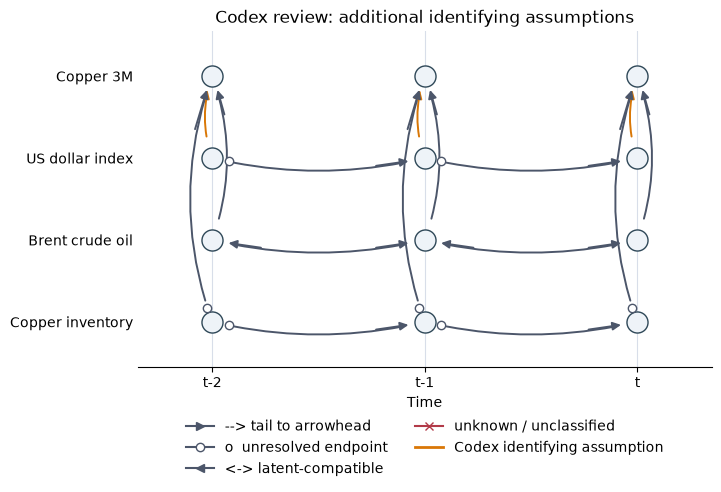

**추가 가정의 근거:** H1 — 추가 식별 가정: 작업모형에서는 달러의 가격표시·해외 수요·금융 경로를 근거로 같은 달 DXY 변화가 구리 가격 변화의 조상이라고 가정한다. IMF WP23/215의 경로 설명과 부합하지만 이 자료에서 식별된 방향은 아니다.

**반론·한계:** 미국 통화정책·세계 수요·위험선호가 두 변수를 함께 움직였을 수 있다. 월간 집계는 월내 순서를 확인하지 못하며 BIS 연구처럼 관계의 부호도 상황에 따라 달라질 수 있다. 순수한 잠재공통원인 설명을 배제한 것은 아니다.

근거 자료: [IMF WP23/215](https://www.imf.org/-/media/files/publications/wp/2023/english/wpiea2023215-print-pdf.pdf), [BIS WP1083](https://www.bis.org/publications/working-paper-1083-commodity-prices-and-us-dollar)

,source,target,edge_count,total_lag,max_edge_lag,path_type,path,timestamps,edge_keys,path_key
0,Com_BrentCrudeOil,Com_LME_Cu_3M,1,0,0,definite,Com_BrentCrudeOil(t+0) -> Com_LME_Cu_3M(t+0),"(0, 0)","(tau0:Com_LME_Cu_3M|Com_BrentCrudeOil,)",Com_BrentCrudeOil(t+0)@0|Com_LME_Cu_3M(t+0)@0|edge:tau0:Com_LME_Cu_3M|Com_BrentCrudeOil:<--|clas...
1,Com_LME_Cu_Inv,Com_LME_Cu_3M,1,0,0,possible,Com_LME_Cu_Inv(t+0) -> Com_LME_Cu_3M(t+0),"(0, 0)","(tau0:Com_LME_Cu_3M|Com_LME_Cu_Inv,)",Com_LME_Cu_Inv(t+0)@0|Com_LME_Cu_3M(t+0)@0|edge:tau0:Com_LME_Cu_3M|Com_LME_Cu_Inv:<-o|class:poss...
2,Idx_DxyUSD,Com_LME_Cu_3M,1,0,0,reviewed_assumption,Idx_DxyUSD(t+0) -> Com_LME_Cu_3M(t+0),"(0, 0)","(tau0:Com_LME_Cu_3M|Idx_DxyUSD,)",Idx_DxyUSD(t+0)@0|Com_LME_Cu_3M(t+0)@0|edge:tau0:Com_LME_Cu_3M|Idx_DxyUSD:<--|class:reviewed_ass...
3,Com_LME_Cu_Inv,Com_LME_Cu_3M,2,1,1,possible,Com_LME_Cu_Inv(t-1) -> Com_LME_Cu_Inv(t+0) -> Com_LME_Cu_3M(t+0),"(-1, 0, 0)","(lag1:Com_LME_Cu_Inv->Com_LME_Cu_Inv, tau0:Com_LME_Cu_3M|Com_LME_Cu_Inv)",Com_LME_Cu_Inv(t-1)@-1|Com_LME_Cu_Inv(t+0)@0|Com_LME_Cu_3M(t+0)@0|edge:lag1:Com_LME_Cu_Inv->Com_...
4,Idx_DxyUSD,Com_LME_Cu_3M,2,1,1,reviewed_assumption,Idx_DxyUSD(t-1) -> Idx_DxyUSD(t+0) -> Com_LME_Cu_3M(t+0),"(-1, 0, 0)","(lag1:Idx_DxyUSD->Idx_DxyUSD, tau0:Com_LME_Cu_3M|Idx_DxyUSD)",Idx_DxyUSD(t-1)@-1|Idx_DxyUSD(t+0)@0|Com_LME_Cu_3M(t+0)@0|edge:lag1:Idx_DxyUSD->Idx_DxyUSD:o->|e...
5,Com_LME_Cu_Inv,Com_LME_Cu_3M,3,2,1,possible,Com_LME_Cu_Inv(t-2) -> Com_LME_Cu_Inv(t-1) -> Com_LME_Cu_Inv(t+0) -> Com_LME_Cu_3M(t+0),"(-2, -1, 0, 0)","(lag1:Com_LME_Cu_Inv->Com_LME_Cu_Inv, lag1:Com_LME_Cu_Inv->Com_LME_Cu_Inv, tau0:Com_LME_Cu_3M|Co...",Com_LME_Cu_Inv(t-2)@-2|Com_LME_Cu_Inv(t-1)@-1|Com_LME_Cu_Inv(t+0)@0|Com_LME_Cu_3M(t+0)@0|edge:la...
6,Idx_DxyUSD,Com_LME_Cu_3M,3,2,1,reviewed_assumption,Idx_DxyUSD(t-2) -> Idx_DxyUSD(t-1) -> Idx_DxyUSD(t+0) -> Com_LME_Cu_3M(t+0),"(-2, -1, 0, 0)","(lag1:Idx_DxyUSD->Idx_DxyUSD, lag1:Idx_DxyUSD->Idx_DxyUSD, tau0:Com_LME_Cu_3M|Idx_DxyUSD)",Idx_DxyUSD(t-2)@-2|Idx_DxyUSD(t-1)@-1|Idx_DxyUSD(t+0)@0|Com_LME_Cu_3M(t+0)@0|edge:lag1:Idx_DxyUS...


In [19]:
raw_graph_snapshot = baseline.graph.copy()
review_applied = False
review_current = CODEX_REVIEW_SIGNATURE == baseline.signature
if review_current:
    display(pd.DataFrame(CODEX_ASSESSMENTS))
    try:
        reviewed_graph, review_decisions = review_graph(
            baseline.graph, baseline.variables, baseline.signature, CODEX_ORIENTATIONS,
        )
        display(review_decisions)
        review_applied = True
    except ValueError as error:
        reviewed_graph = baseline.graph.copy()
        display(Markdown(f"검토 적용 거부: {error}. 원래 PAG를 유지합니다."))
else:
    reviewed_graph = baseline.graph.copy()
    display(Markdown("현재 실행과 일치하는 Codex 검토가 없습니다. 원래 PAG를 유지하고 재검토가 필요합니다."))

assert np.array_equal(raw_graph_snapshot, baseline.graph), "원래 PAG가 변경되었습니다."
if review_applied and CODEX_ORIENTATIONS:
    assumed_keys = review_decisions.edge_key.tolist()
    plot_pag(reviewed_graph, baseline.variables, title="Codex review: additional identifying assumptions",
             assumed_edges=assumed_keys)
    plt.show()
    for decision in CODEX_ORIENTATIONS:
        display(Markdown('**추가 가정의 근거:** ' + decision['rationale'] + '\n\n**반론·한계:** ' + decision['counterargument']))
        display(Markdown('근거 자료: [IMF WP23/215](' + IMF_MONETARY + '), [BIS WP1083](' + BIS_DOLLAR + ')'))
    display(upstream_paths(reviewed_graph, baseline.variables, baseline.target,
                           assumed_edges=assumed_keys).head(40))
elif review_applied:
    display(Markdown("검토는 완료되었으며 추가 방향을 강제하지 않았습니다. 원래 PAG와 보완 후 그래프가 같습니다."))


In [20]:
if review_current and review_applied:
    display(Markdown("""
### 현재 결과의 해석

- 원래 기본 PAG에서 구리 가격과 연결된 세 외부 변수는 모두 **lag 0**입니다.
  기본 설정에서 **다른 변수의 과거 값이 구리 가격으로 바로 들어오는 lag 1–2 간선은 발견되지 않았습니다.**
  이는 관계가 존재하지 않는다는 증명이나 실무적 선행성 검증 결과가 아닙니다.
- 달러·재고의 음의 부분상관, 브렌트유의 양의 부분상관은 경제적 설명 후보와 부합합니다.
  숫자를 가격 영향의 크기나 방향의 확률로 해석하지 않습니다.
- Codex는 **DXY → 구리**를 명시적인 작업가설 H1로 추가하고, 재고 방향은 미확정으로 남겼습니다.
  H1을 포함한 경로에는 `reviewed_assumption`을 표시합니다.
  이러한 경로는 다른 미확정 끝점도 포함할 수 있으므로 완성·검증된 DAG 경로가 아닙니다.
- 기간·alpha·시차·현물·가상 지연을 바꾼 재등장 표를 함께 읽어야 합니다.
  지연 가정에 따른 간선 이동은 당시 이용 가능했던 자료의 증거가 아닙니다.
- 다음 확장은 변수 정의·발표 빈티지 확인 후 수요·공급 변수를 보강하는 것입니다.
  이번 Notebook에서는 인과효과 추정이나 예측 실험으로 범위를 넓히지 않습니다.
"""))
else:
    display(Markdown("현재 실행에 유효하게 적용된 검토가 없어 이전 해석을 표시하지 않습니다. 현재 출력의 Codex 재검토가 필요합니다."))



### 현재 결과의 해석

- 원래 기본 PAG에서 구리 가격과 연결된 세 외부 변수는 모두 **lag 0**입니다.
  기본 설정에서 **다른 변수의 과거 값이 구리 가격으로 바로 들어오는 lag 1–2 간선은 발견되지 않았습니다.**
  이는 관계가 존재하지 않는다는 증명이나 실무적 선행성 검증 결과가 아닙니다.
- 달러·재고의 음의 부분상관, 브렌트유의 양의 부분상관은 경제적 설명 후보와 부합합니다.
  숫자를 가격 영향의 크기나 방향의 확률로 해석하지 않습니다.
- Codex는 **DXY → 구리**를 명시적인 작업가설 H1로 추가하고, 재고 방향은 미확정으로 남겼습니다.
  H1을 포함한 경로에는 `reviewed_assumption`을 표시합니다.
  이러한 경로는 다른 미확정 끝점도 포함할 수 있으므로 완성·검증된 DAG 경로가 아닙니다.
- 기간·alpha·시차·현물·가상 지연을 바꾼 재등장 표를 함께 읽어야 합니다.
  지연 가정에 따른 간선 이동은 당시 이용 가능했던 자료의 증거가 아닙니다.
- 다음 확장은 변수 정의·발표 빈티지 확인 후 수요·공급 변수를 보강하는 것입니다.
  이번 Notebook에서는 인과효과 추정이나 예측 실험으로 범위를 넓히지 않습니다.


## 9. 재현·완료 확인

검증 대상은 데이터/시점 처리, 간선 표현과 검토 적용, 재실행 일관성입니다. 합성 간선 테스트는 통계적 인과 발견의 정확도나 참 DAG 복원을 입증하는 시험이 아닙니다. 기본 실행을 한 번 더 반복하고 원본 데이터·원래 그래프 보존을 확인합니다.

완료 조건은 정해진 분석·안정성 비교·현재 결과의 Codex 검토·전체 Notebook 재실행입니다. 빈 그래프나 안정적이지 않은 관계도 정상적인 탐색 결과입니다.

In [21]:
repeat = rerun_result(baseline)
assert repeat.signature == baseline.signature
assert np.array_equal(repeat.graph, baseline.graph)
assert np.allclose(repeat.val_matrix, baseline.val_matrix, equal_nan=True)
assert np.allclose(repeat.p_matrix, baseline.p_matrix, equal_nan=True)
assert sha256(DATA_PATH.read_bytes()).hexdigest() == INPUT_HASH
assert np.array_equal(raw_graph_snapshot, baseline.graph)
assert len(results) == 7
display(pd.DataFrame([{
    "analysis_runs": len(results), "deterministic_repeat": "PASS",
    "raw_csv_unchanged": "PASS", "raw_pag_unchanged": "PASS",
    "codex_review_matches_run": review_current,
    "codex_review_applied": review_applied,
    "baseline_adjacencies": len(baseline_edges),
    "bounded_upstream_routes": len(baseline_paths),
    "actual_point_in_time_validation": "미검증: 발표일·빈티지 자료 없음",
}]))


,analysis_runs,deterministic_repeat,raw_csv_unchanged,raw_pag_unchanged,codex_review_matches_run,codex_review_applied,baseline_adjacencies,bounded_upstream_routes,actual_point_in_time_validation
0,7,PASS,PASS,PASS,True,True,6,7,미검증: 발표일·빈티지 자료 없음


## 10. 변수·파라미터·분석창의 안정성 탐색

위 1–9절은 최초 고정 프로토타입의 결과입니다. 이 절에서는 **실험 전에 고정한 기준**으로 변수 조합·검정·시차·분석창을 비교합니다. 실제 구리 시장의 정답 DAG가 없으므로, 여기서 평가하는 것은 구조의 정답률이 아니라 **관측된 관계와 방향의 재현성**입니다. LLM이 추가한 H1은 선정·평가에 사용하지 않습니다.

- **72개 조건:** 변수군 6개 × ParCorr/RobustParCorr × 최대시차 1/2 × alpha 0.01/0.03/0.05.
- **360회 개발 비교:** 첫 96개월 안의 96개월 전체, 앞/뒤 72개월, 앞/뒤 84개월. 창은 겹치므로 독립적인 반복 실험이 아닙니다.
- **선정 후 검증:** 개발 결과만으로 변수군별 최선 조건을 정하고 최대 3개를 고정합니다. 이후 후기 37개월, 전체 133개월, 108/120개월 창, 현물 교체, 최대시차 3을 확인합니다. 후기 자료도 과거 기본 분석에서 본 자료이므로 완전히 새로운 holdout은 아닙니다.
- **특정 기간 의존성:** 달력을 압축하지 않고 11개 연도 블록을 각각 제외합니다. 특히 2020년과 2022년 제외에서 연결과 부호가 유지되어야 높은 안정성 등급을 부여합니다.
- **정렬 대조:** 설명변수를 함께 19번 순환 이동하고 연결 검출 빈도를 확인합니다. 시계열 결합 경계를 건너는 CI 표본은 제외합니다. 이것은 정식 permutation p-value나 FDR 보장이 아닙니다.

분석창 길이에 보편적인 최적값은 없습니다. LPCMCI 연구의 표본 수·조건집합 차원·정상성 가정을 고려해 이 범위를 정했습니다. RobustParCorr는 주변분포를 정규화하는 비교이며, 모든 비선형성·이분산을 해결하지 않습니다.

**등급 기준은 운영상 선택 규칙이지 인과 확률이 아닙니다.** 연결은 개발 창 80% 이상, 연도 제외 80% 이상, 부호 일치 90% 이상, 추가 검증 80% 이상, 정렬 대조 검출 최대 1/19 및 주요 연도 제외를 요구합니다. 방향 등급에는 원래 PAG의 확정 꼬리·화살촉, 반대 조상성 정보의 부재, 후기 구간 확인을 추가로 요구합니다. 짧은 후기 창에서 미검출된 경우에는 낮은 검정력 가능성을 함께 남깁니다.

전체 실행표와 실패 기록은 `artifacts/stability_search/<실험 서명>/results.json`에 저장합니다. 원본 데이터·프로토콜·분석 정의 코드·패키지 버전이 같을 때만 기록을 재사용하며, 새로운 조건은 다른 서명에 보존합니다. 좋은 결과만 골라 기준을 바꾸거나 검증 구간에 맞춰 다시 튜닝하지 않습니다.

In [22]:
# Frozen, finite stability-search protocol. This is descriptive discovery, not effect estimation.
SEARCH_PROTOCOL = {
    "schema_version": "causal-stability-search-v1",
    "seed": 20260914,
    "target": "Com_LME_Cu_3M",
    "cash_target": "Com_LME_Cu_Cash",
    "input_sets": {
        "base": ["Idx_DxyUSD", "Com_BrentCrudeOil", "Com_LME_Cu_Inv"],
        "shfe": ["Idx_DxyUSD", "Com_BrentCrudeOil", "Com_SHFE_Cu_Inv"],
        "cme": ["Idx_DxyUSD", "Com_BrentCrudeOil", "Com_CME_Cu_inv"],
        "shanghai": ["Idx_DxyUSD", "Com_BrentCrudeOil", "Com_LME_Cu_Inv", "Idx_Shanghai"],
        "sp500": ["Idx_DxyUSD", "Com_BrentCrudeOil", "Com_LME_Cu_Inv", "Idx_SnP500"],
        "gold_vix": ["Idx_DxyUSD", "Com_LME_Cu_Inv", "Com_Gold", "Idx_SnPVIX"],
    },
    "ci_tests": ["ParCorr", "RobustParCorr"],
    "tau_max_values": [1, 2],
    "pc_alpha_values": [0.01, 0.03, 0.05],
    "algorithm": {"tau_min": 0, "n_preliminary_iterations": 1, "max_p_non_ancestral": 3},
    "reference_burn": 6,
    "dev_raw_n": 96,
    "dev_windows": {"full96": [0, 96], "first72": [0, 72], "last72": [24, 96], "first84": [0, 84], "last84": [12, 96]},
    "validation_windows": {"late37": [96, 133], "full133": [0, 133], "first108": [0, 108], "last108": [25, 133], "first120": [0, 120], "last120": [13, 133]},
    "jackknife_block_months": 12,
    "jackknife_raw_blocks": [[0, 12], [12, 24], [24, 36], [36, 48], [48, 60], [60, 72], [72, 84], [84, 96], [96, 108], [108, 120], [120, 133]],
    "null_rolls": 19,
    "null_min_offset": 12,
    "selection": {"adjacency": 0.8, "sign": 0.8, "incoming": 0.8, "max_distinct_input_sets": 3},
    "final": {"dev_adjacency": 0.8, "jackknife_adjacency": 0.8, "sign": 0.9, "extended_presence": 0.8, "null_frequency": 0.10, "incoming": 0.8},
    "caveats": [
        "LPCMCI PAG discovery does not identify or estimate a causal effect.",
        "Stability and disturbance checks do not guarantee causal recovery.",
        "The late window is low-power and is not pristine new data because earlier baseline inspection used the series.",
        "Circular-roll and block-deletion checks are empirical stress tests, not CI tests or FDR probabilities.",
    ],
}

SEARCH_SUPPORTED_MARKS = {"-->", "<--", "<->", "o-o", "o->", "<-o"}

def search_json_safe(value):
    if isinstance(value, dict):
        return {str(k): search_json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [search_json_safe(v) for v in list(value)]
    if isinstance(value, (pd.Timestamp, np.datetime64)):
        return pd.Timestamp(value).isoformat()
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value

def search_configs(protocol=None):
    protocol = protocol or SEARCH_PROTOCOL
    rows = []
    for input_id, inputs in protocol["input_sets"].items():
        for ci_name in protocol["ci_tests"]:
            for tau_max in protocol["tau_max_values"]:
                for alpha in protocol["pc_alpha_values"]:
                    config_id = f"{input_id}__{ci_name.lower()}__t{tau_max}__a{str(alpha).replace('.', 'p')}"
                    rows.append({"id": config_id, "input_set": input_id, "inputs": list(inputs), "ci_test": ci_name, "tau_max": int(tau_max), "pc_alpha": float(alpha)})
    return rows

def search_protocol_copy(overrides=None):
    protocol = json.loads(json.dumps(SEARCH_PROTOCOL))
    for key, value in (overrides or {}).items():
        protocol[key] = value
    return protocol


In [23]:
def search_definition_sha256(notebook_path):
    notebook = json.loads(Path(notebook_path).read_text(encoding="utf-8"))
    definition_tags = {"causal-definitions", "causal-experiment-definitions"}
    tagged = [{"id": cell.get("id"), "source": cell.get("source", [])} for cell in notebook.get("cells", []) if definition_tags.intersection(cell.get("metadata", {}).get("tags", []))]
    if not tagged:
        raise ValueError("Notebook has no tagged causal definition cells")
    payload = json.dumps(tagged, sort_keys=True, separators=(",", ":"), ensure_ascii=False)
    return sha256(payload.encode()).hexdigest()

def search_manifest(raw, protocol, notebook_path, configs):
    return {"schema_version": protocol["schema_version"], "input_sha256": raw.attrs.get("input_sha256"), "protocol": protocol, "configs": configs, "package_versions": _package_versions(), "search_definition_sha256": search_definition_sha256(notebook_path)}

def search_manifest_hash(manifest):
    payload = json.dumps(search_json_safe(manifest), sort_keys=True, separators=(",", ":"), allow_nan=False)
    return sha256(payload.encode()).hexdigest()

def search_atomic_write(path, document):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(search_json_safe(document), indent=2, sort_keys=True, allow_nan=False), encoding="utf-8")
    temporary.replace(path)

def search_reference_points(frame_n, burn=6, excluded_raw_blocks=None, shift=None):
    refs = np.arange(int(burn), int(frame_n), dtype=int)
    keep = np.ones(len(refs), dtype=bool)
    for start, stop in excluded_raw_blocks or []:
        # Reference r is raw time t=r+1; frozen raw support [t-7,t] is [r-6,r+1].
        keep &= ~((refs + 1 >= int(start)) & (refs - int(burn) < int(stop)))
    if shift is not None:
        seam = int(shift)
        keep &= ~((refs - int(burn) < seam) & (seam <= refs))
    return refs[keep]

def search_ci_test(name, seed):
    from tigramite.independence_tests.parcorr import ParCorr
    from tigramite.independence_tests.robust_parcorr import RobustParCorr
    if name not in {"ParCorr", "RobustParCorr"}: raise ValueError(f"Unsupported frozen CI test: {name}")
    return (ParCorr if name == "ParCorr" else RobustParCorr)(seed=int(seed))

def search_instrument_ci(ci, diagnostics):
    original_run = ci.run_test
    original_measure = ci.get_dependence_measure
    def recorded_run(X, Y, Z=None, tau_max=0, cut_off="2xtau_max", alpha_or_thres=None):
        nodes = list(X) + list(Y) + list(Z or [])
        max_node_lag = max([0, *[-int(node[1]) for node in nodes]])
        event = {"X": search_json_safe(X), "Y": search_json_safe(Y), "Z_n": len(Z or []), "tau_max_argument": int(tau_max), "max_node_lag": max_node_lag, "cut_off": cut_off}
        diagnostics["run_test_events"].append(event)
        if max_node_lag > 6:
            raise RuntimeError(f"CI test requested actual node lag {max_node_lag}, beyond the frozen six-month guard")
        return original_run(X=X, Y=Y, Z=Z, tau_max=tau_max, cut_off=cut_off, alpha_or_thres=alpha_or_thres)
    def recorded_measure(array, xyz, data_type=None):
        actual_t = int(array.shape[1])
        df = actual_t - int(array.shape[0])
        event = {"actual_T": actual_t, "conditioning_dim": max(0, int(array.shape[0]) - 2), "df": df}
        diagnostics["dependence_events"].append(event)
        if df <= 0:
            raise RuntimeError(f"Non-positive ParCorr degrees of freedom: {df}")
        return original_measure(array=array, xyz=xyz, data_type=data_type)
    ci.run_test = recorded_run
    ci.get_dependence_measure = recorded_measure
    return ci

def search_compact_diagnostics(diagnostics):
    run_events, dep_events = diagnostics["run_test_events"], diagnostics["dependence_events"]
    lag_counts = {}
    for event in run_events: lag_counts[str(event["max_node_lag"])] = lag_counts.get(str(event["max_node_lag"]), 0) + 1
    t_counts = {}
    for event in dep_events: t_counts[str(event["actual_T"])] = t_counts.get(str(event["actual_T"]), 0) + 1
    return {"run_test_count": len(run_events), "dependence_measure_count": len(dep_events), "actual_node_lag_counts": lag_counts, "actual_T_counts": t_counts, "min_df": min((e["df"] for e in dep_events), default=None), "max_conditioning_dim": max((e["conditioning_dim"] for e in dep_events), default=None)}

def search_fit(raw_slice, config, reference_exclude_blocks=None, shift=None, target=TARGET):
    from tigramite import data_processing as pp
    from tigramite.lpcmci import LPCMCI
    variables = [target, *config["inputs"]]
    started = time.perf_counter()
    record = {"config_id": config["id"], "target": target, "variables": variables, "seed": int(config.get("seed", SEARCH_PROTOCOL["seed"])), "status": "failed", "errors": []}
    diagnostics = {"run_test_events": [], "dependence_events": []}
    try:
        raw_slice = raw_slice.loc[:, variables].copy()
        frame = preprocess_logdiff(raw_slice, variables).iloc[1:].copy()
        if frame.isna().any().any() or not np.isfinite(frame.to_numpy(dtype=float)).all():
            raise ValueError("Search frame must be complete and finite")
        if shift is not None:
            shift = int(shift)
            frame.loc[:, config["inputs"]] = np.roll(frame.loc[:, config["inputs"]].to_numpy(), shift=shift, axis=0)
        refs = search_reference_points(len(frame), SEARCH_PROTOCOL["reference_burn"], reference_exclude_blocks, shift)
        if not len(refs):
            raise ValueError("No safe reference points remain")
        dataframe = pp.DataFrame(frame.to_numpy(dtype=float, copy=True), var_names=variables, datatime=frame.index.to_numpy(copy=True), reference_points=refs.copy())
        ci = search_ci_test(config["ci_test"], record["seed"])
        model = LPCMCI(dataframe=dataframe, cond_ind_test=ci, verbosity=0)
        model.cond_ind_test = search_instrument_ci(model.cond_ind_test, diagnostics)
        output = model.run_lpcmci(link_assumptions=build_link_assumptions(variables, int(config["tau_max"])), tau_min=0, tau_max=int(config["tau_max"]), pc_alpha=float(config["pc_alpha"]), n_preliminary_iterations=1, max_p_non_ancestral=3)
        dep = diagnostics["dependence_events"]
        requested = [e["max_node_lag"] for e in diagnostics["run_test_events"]]
        record.update(status="complete", graph=np.asarray(output["graph"]).tolist(), val_matrix=search_json_safe(np.asarray(output["val_matrix"], dtype=float)), p_matrix=search_json_safe(np.asarray(output["p_matrix"], dtype=float)), reference_points=refs.tolist(), reference_point_dates=[pd.Timestamp(frame.index[i]).strftime("%Y-%m") for i in refs], effective_n=int(len(refs)), transformed_n=int(len(frame)), raw_n=int(len(raw_slice)), raw_date_bounds=[pd.Timestamp(raw_slice.index.min()).strftime("%Y-%m"), pd.Timestamp(raw_slice.index.max()).strftime("%Y-%m")], max_requested_lag=max(requested, default=None), min_df=min((e["df"] for e in dep), default=None), max_conditioning_dim=max((e["conditioning_dim"] for e in dep), default=None), diagnostics=search_compact_diagnostics(diagnostics))
    except Exception as exc:
        record["errors"].append({"type": type(exc).__name__, "message": str(exc)})
        record["diagnostics"] = search_compact_diagnostics(diagnostics)
    record["elapsed_seconds"] = float(time.perf_counter() - started)
    return search_json_safe(record)

def search_attempt_key(phase, window, config_id, variant="standard", seed=None):
    return "|".join(map(str, [phase, window, config_id, variant, seed if seed is not None else ""]))

def search_add_attempt(document, result_path, raw_slice, config, phase, window, variant="standard", seed=None, **fit_kwargs):
    key = search_attempt_key(phase, window, config["id"], variant, seed)
    if any(row["record_key"] == key and row["status"] == "complete" for row in document["attempts"]):
        return
    attempt = search_fit(raw_slice, dict(config, seed=seed or document["protocol"]["seed"]), **fit_kwargs)
    attempt.update(record_key=key, phase=phase, window=window, variant=variant, retry_count=sum(row.get("record_key") == key for row in document["attempts"]))
    document["attempts"].append(attempt)
    if attempt["status"] != "complete" or len(document["attempts"]) % 5 == 0: search_atomic_write(result_path, document)

def search_run(data_path, cache_root, progress=True, notebook_path="02. prototype.ipynb", configs=None, protocol_override=None):
    protocol = search_protocol_copy(protocol_override)
    raw = load_data(data_path)
    if len(raw) < max(stop for bounds in protocol["validation_windows"].values() for stop in [bounds[1]]):
        raise ValueError("Input does not cover every frozen raw window")
    chosen_configs = [dict(c) for c in (configs or search_configs(protocol))]
    manifest = search_manifest(raw, protocol, notebook_path, chosen_configs)
    manifest_hash = search_manifest_hash(manifest)
    result_path = Path(cache_root) / manifest_hash / "results.json"
    if result_path.exists():
        document = json.loads(result_path.read_text(encoding="utf-8"))
        if document.get("manifest") != search_json_safe(manifest):
            raise RuntimeError("Cache manifest mismatch; refusing reuse")
    else:
        document = {"schema_version": protocol["schema_version"], "manifest": search_json_safe(manifest), "manifest_hash": manifest_hash, "protocol": protocol, "configs": chosen_configs, "attempts": [], "frozen_selection": None, "selection_status": "pending", "evaluation": None, "status": "dev_running", "notes": list(protocol["caveats"])}
        search_atomic_write(result_path, document)
    for config in chosen_configs:
        for window, (start, stop) in protocol["dev_windows"].items():
            if progress: print(f"dev {config['id']} {window}")
            search_add_attempt(document, result_path, raw.iloc[start:stop], config, "dev", window)
    required_dev = len(chosen_configs) * len(protocol["dev_windows"])
    complete_dev = [r for r in document["attempts"] if r["phase"] == "dev" and r["status"] == "complete"]
    if len(complete_dev) != required_dev:
        document["status"] = "incomplete_dev"; search_atomic_write(result_path, document)
        raise RuntimeError(f"Incomplete required development fits: {len(complete_dev)}/{required_dev}")
    if document["frozen_selection"] is None:
        ranked = search_rank(document["attempts"], chosen_configs, expected_dev_windows=len(protocol["dev_windows"]), protocol=protocol)
        eligible = ranked.loc[ranked["n_stable_adj"] > 0]
        selected, used = [], set()
        for config_id in eligible["config_id"].tolist():
            config = next(c for c in chosen_configs if c["id"] == config_id)
            if config["input_set"] not in used:
                selected.append(config_id); used.add(config["input_set"])
            if len(selected) == int(protocol["selection"]["max_distinct_input_sets"]): break
        null_allowed = np.arange(int(protocol["null_min_offset"]), 132 - int(protocol["null_min_offset"]) + 1)
        null_offsets = sorted(map(int, np.random.default_rng(int(protocol["seed"])).choice(null_allowed, size=int(protocol["null_rolls"]), replace=False)))
        jackknife_blocks = [tuple(x) for x in protocol["jackknife_raw_blocks"]]
        document["frozen_selection"] = selected
        document["null_offsets"] = null_offsets
        document["jackknife_blocks"] = [list(x) for x in jackknife_blocks]
        document["full_same_input_grid"] = {cid: [c["id"] for c in chosen_configs if c["input_set"] == next(x for x in chosen_configs if x["id"] == cid)["input_set"]] for cid in selected}
        document["null_design"] = {"transformed_n": 132, "operation": "positive np.roll applied jointly to transformed predictors", "seam_guard": "exclude references whose transformed [t-6,t] history crosses the roll seam", "seed": int(protocol["seed"]), "offsets": null_offsets}
        document["validation_plan"] = {cid: [*[f"validation:{w}" for w in protocol["validation_windows"]], "validation:cash133", "validation:lag3_133", *[f"jackknife:raw_{a}_{b}" for a, b in jackknife_blocks], *[f"null:roll_{offset}" for offset in null_offsets]] for cid in selected}
        document["selection_status"] = "selected" if selected else "no_candidate"
        document["status"] = "selection_frozen"; search_atomic_write(result_path, document)
    for config_id in document["frozen_selection"]:
        config = next(c for c in chosen_configs if c["id"] == config_id)
        for window, (start, stop) in protocol["validation_windows"].items():
            search_add_attempt(document, result_path, raw.iloc[start:stop], config, "validation", window)
        cash_config = dict(config, id=config["id"] + "__cash")
        search_add_attempt(document, result_path, raw.iloc[:133], cash_config, "validation", "cash133", target=protocol["cash_target"] )
        lag3_config = dict(config, id=config["id"] + "__lag3", tau_max=3)
        search_add_attempt(document, result_path, raw.iloc[:133], lag3_config, "validation", "lag3_133")
        for start, stop in document["jackknife_blocks"]:
            search_add_attempt(document, result_path, raw.iloc[:133], config, "jackknife", f"raw_{start}_{stop}", variant="reference_exclusion", reference_exclude_blocks=[(start, stop)])
        for offset in document["null_offsets"]:
            search_add_attempt(document, result_path, raw.iloc[:133], config, "null", f"roll_{offset}", variant="joint_predictor_roll", seed=int(protocol["seed"]), shift=offset)
    selected_n = len(document["frozen_selection"] or [])
    required_validation = sum(len(v) for v in document.get("validation_plan", {}).values())
    complete_validation = [r for r in document["attempts"] if r["phase"] != "dev" and r["status"] == "complete"]
    if len(complete_validation) != required_validation:
        document["status"] = "incomplete_validation"; search_atomic_write(result_path, document)
        raise RuntimeError(f"Incomplete required validation fits: {len(complete_validation)}/{required_validation}")
    document["evaluation"] = search_evaluate(document)
    document["status"] = "complete"; search_atomic_write(result_path, document)
    return document


In [24]:
def search_target_links(record):
    if record.get("status") != "complete": return {}
    target_index = record["variables"].index(record["target"])
    graph, values = np.asarray(record["graph"]), np.asarray(record["val_matrix"], dtype=object)
    links = {}
    for source_index, source in enumerate(record["variables"]):
        for lag in range(graph.shape[2]):
            if source_index == target_index: continue
            mark = str(graph[source_index, target_index, lag])
            if not mark: continue
            value = values[source_index, target_index, lag]
            finite_value = value is not None and np.isfinite(float(value))
            links[(source, lag)] = {"mark": mark, "supported": mark in SEARCH_SUPPORTED_MARKS, "sign": int(np.sign(float(value))) if finite_value else None, "value": float(value) if finite_value else None}
    return links

def search_link_stability(records, config_id, phase="dev"):
    candidates = [r for r in records if r.get("phase") == phase and r.get("config_id") == config_id]
    latest = {}
    for row in candidates:
        key = row.get("record_key", f"{row.get('phase')}|{row.get('window')}|{row.get('config_id')}")
        if key not in latest or row.get("status") == "complete": latest[key] = row
    rows = list(latest.values())
    completed = [r for r in rows if r.get("status") == "complete"]
    denominator = len(rows)
    keys = sorted(set().union(*(search_target_links(r).keys() for r in completed))) if completed else []
    output = {}
    for key in keys:
        observed = [search_target_links(r).get(key) if r.get("status") == "complete" else None for r in rows]
        promoted = [x for x in observed if x and x["supported"]]
        marks = [x["mark"] for x in promoted]
        signs = [x["sign"] for x in promoted if x["sign"] not in (None, 0)]
        modal_mark = max(set(marks), key=lambda x: (marks.count(x), x)) if marks else None
        output[key] = {"variable": key[0], "lag": key[1], "denominator": denominator, "complete": len(completed), "failed": denominator - len(completed), "adjacency_frequency": len(promoted) / denominator if denominator else None, "modal_mark": modal_mark, "modal_exact_frequency": marks.count(modal_mark) / denominator if denominator and modal_mark else 0.0, "incoming_frequency": marks.count("-->") / denominator if denominator else None, "opposite_frequency": marks.count("<--") / denominator if denominator else None, "source_arrowhead_frequency": sum(m in {"<--", "<-o", "<->"} for m in marks) / denominator if denominator else None, "sign_agreement": max(signs.count(-1), signs.count(1)) / len(signs) if signs else 0.0, "modal_sign": max(set(signs), key=lambda x: signs.count(x)) if signs else None, "unsupported_count": sum(bool(x and not x["supported"]) for x in observed)}
    return output

def search_rank(records, configs, expected_dev_windows=None, protocol=None):
    protocol = protocol or SEARCH_PROTOCOL
    expected_dev_windows = len(protocol["dev_windows"]) if expected_dev_windows is None else int(expected_dev_windows)
    rows = []
    for config in configs:
        stability = search_link_stability(records, config["id"])
        dev_latest = {r.get("record_key", r.get("window")): r for r in records if r.get("phase") == "dev" and r.get("config_id") == config["id"]}
        complete_windows = sum(r.get("status") == "complete" for r in dev_latest.values()); failed_windows = len(dev_latest) - complete_windows
        eligible_config = failed_windows == 0 and complete_windows == expected_dev_windows
        stable = [v for v in stability.values() if eligible_config and v["adjacency_frequency"] >= protocol["selection"]["adjacency"] and v["sign_agreement"] >= protocol["selection"]["sign"]]
        directed = [v for v in stable if v["incoming_frequency"] >= protocol["selection"]["incoming"]]
        intermittent = sum(0 < v["adjacency_frequency"] < protocol["selection"]["adjacency"] for v in stability.values())
        n_inputs = len(config["inputs"]); opportunities = n_inputs * (int(config["tau_max"]) + 1)
        stable_lag0 = sum(v["lag"] == 0 for v in stable); stable_lagged = len(stable) - stable_lag0
        rows.append({"config_id": config["id"], "input_set": config["input_set"], "complete_dev_windows": complete_windows, "failed_dev_windows": failed_windows, "eligible_config": eligible_config, "n_stable_directed": len(directed), "n_stable_adj": len(stable), "stable_directed_rate": len(directed) / opportunities, "stable_adj_rate": len(stable) / opportunities, "stable_lag0_rate": stable_lag0 / n_inputs, "stable_lagged_rate": stable_lagged / (n_inputs * int(config["tau_max"])), "mean_modal_rate_on_stable": float(np.mean([v["modal_exact_frequency"] for v in stable])) if stable else 0.0, "intermittent_links": intermittent, "intermittent_rate": intermittent / opportunities, "eligible_opportunities": opportunities, "n_explanatory": n_inputs, "pc_alpha": config["pc_alpha"], "tau_max": config["tau_max"], "ci_test": config["ci_test"]})
    table = pd.DataFrame(rows)
    if table.empty: return table
    table["ci_order"] = table["ci_test"].map({"ParCorr": 0, "RobustParCorr": 1}).fillna(9)
    return table.sort_values(["complete_dev_windows", "stable_directed_rate", "stable_adj_rate", "mean_modal_rate_on_stable", "intermittent_rate", "n_explanatory", "pc_alpha", "tau_max", "ci_order", "config_id"], ascending=[False, False, False, False, True, True, True, True, True, True]).drop(columns="ci_order").reset_index(drop=True)

def search_presence(records, config_id, phase, windows, key):
    candidates = [r for r in records if r.get("phase") == phase and r.get("window") in windows and (r.get("config_id") == config_id or r.get("config_id", "").startswith(config_id + "__"))]
    latest = {}
    for row in candidates:
        planned_key = row.get("window")
        if planned_key not in latest or row.get("status") == "complete": latest[planned_key] = row
    eligible = [r for r in latest.values() if r.get("status") == "complete" and key[1] < np.asarray(r["graph"]).shape[2]]
    values = [search_target_links(r).get(key) for r in eligible]
    promoted = [x for x in values if x and x["supported"]]
    signs = [x["sign"] for x in promoted if x["sign"] not in (None, 0)]
    marks = [x["mark"] for x in promoted]
    modal = max(set(marks), key=lambda x: (marks.count(x), x)) if marks else None
    denominator = len(windows)
    failed = denominator - len(eligible)
    return {"denominator": denominator, "complete": len(eligible), "failed": failed, "present": len(promoted), "adjacency_frequency": len(promoted) / denominator if denominator else None, "sign_agreement": max(signs.count(-1), signs.count(1)) / len(signs) if signs else 0.0, "modal_sign": max(set(signs), key=lambda x: signs.count(x)) if signs else None, "modal_mark": modal, "modal_exact_frequency": marks.count(modal) / denominator if denominator and modal else 0.0, "incoming_frequency": marks.count("-->") / denominator if denominator else None, "opposite_frequency": marks.count("<--") / denominator if denominator else None, "source_arrowhead_frequency": sum(m in {"<--", "<-o", "<->"} for m in marks) / denominator if denominator else None}

def search_evaluate(document):
    records, configs, protocol = document["attempts"], document["configs"], document["protocol"]
    selected_rows, neighbor_rows = [], []
    extended_windows = {"first108", "last108", "first120", "last120", "cash133", "lag3_133"}
    jack_windows = {f"raw_{start}_{stop}" for start, stop in protocol["jackknife_raw_blocks"]}
    null_offsets = document.get("null_offsets", document.get("null_design", {}).get("offsets", []))
    null_windows = {f"roll_{offset}" for offset in null_offsets}
    for config_id in document.get("frozen_selection") or []:
        dev = search_link_stability(records, config_id)
        config = next(c for c in configs if c["id"] == config_id)
        stable_keys = {k for k, v in dev.items() if v["failed"] == 0 and v["denominator"] == len(protocol["dev_windows"]) and v["adjacency_frequency"] >= protocol["selection"]["adjacency"] and v["sign_agreement"] >= protocol["selection"]["sign"]}
        for other in [c for c in configs if c["input_set"] == config["input_set"]]:
            other_stable = search_link_stability(records, other["id"])
            retained = sum(k in other_stable and other_stable[k]["failed"] == 0 and other_stable[k]["adjacency_frequency"] >= protocol["selection"]["adjacency"] and other_stable[k]["sign_agreement"] >= protocol["selection"]["sign"] for k in stable_keys)
            neighbor_rows.append({"selected_config_id": config_id, "neighbor_config_id": other["id"], "ci_test": other["ci_test"], "tau_max": other["tau_max"], "pc_alpha": other["pc_alpha"], "retained": retained, "denominator": len(stable_keys), "retention": retained / len(stable_keys) if stable_keys else None})
        for key in sorted(stable_keys):
            full = search_presence(records, config_id, "validation", {"full133"}, key)
            late = search_presence(records, config_id, "validation", {"late37"}, key)
            extended = search_presence(records, config_id, "validation", extended_windows, key)
            jack = search_presence(records, config_id, "jackknife", jack_windows, key)
            null = search_presence(records, config_id, "null", null_windows, key)
            shock2020 = search_presence(records, config_id, "jackknife", {"raw_60_72"}, key)
            shock2022 = search_presence(records, config_id, "jackknife", {"raw_84_96"}, key)
            d = dev[key]; final = protocol["final"]
            same_sign = d["modal_sign"] is not None and jack["modal_sign"] == d["modal_sign"]
            late_sign_conflict = late["present"] > 0 and late["modal_sign"] is not None and late["modal_sign"] != d["modal_sign"]
            complete_plan = full["denominator"] == full["complete"] == 1 and late["denominator"] == late["complete"] == 1 and extended["denominator"] == extended["complete"] == 6 and jack["denominator"] == jack["complete"] == len(protocol["jackknife_raw_blocks"]) and null["denominator"] == null["complete"] == int(protocol["null_rolls"])
            shocks_retained = all(s["present"] == 1 and s["modal_sign"] == d["modal_sign"] and s["failed"] == 0 for s in (shock2020, shock2022))
            null_limit = int(np.floor(int(protocol["null_rolls"]) * float(final["null_frequency"])))
            pre_shock_association = complete_plan and not late_sign_conflict and d["adjacency_frequency"] >= final["dev_adjacency"] and d["sign_agreement"] >= final["sign"] and full["present"] == 1 and full["modal_sign"] == d["modal_sign"] and full["sign_agreement"] >= final["sign"] and jack["adjacency_frequency"] is not None and jack["adjacency_frequency"] >= final["jackknife_adjacency"] and jack["sign_agreement"] >= final["sign"] and same_sign and extended["adjacency_frequency"] is not None and extended["adjacency_frequency"] >= final["extended_presence"] and extended["sign_agreement"] >= final["sign"] and extended["modal_sign"] == d["modal_sign"] and null["present"] <= null_limit
            association = pre_shock_association and shocks_retained
            no_opposite = all(x["source_arrowhead_frequency"] == 0 for x in (d, jack, full, extended))
            direction = association and d["incoming_frequency"] >= final["incoming"] and jack["incoming_frequency"] >= final["incoming"] and full["modal_mark"] == "-->" and no_opposite
            late_matching = late["modal_mark"] == "-->" and late["modal_sign"] == d["modal_sign"]
            late_status = "temporally-unconfirmed" if late["present"] == 0 else ("matching-directed" if late_matching else ("conflict" if late["modal_mark"] in {"<--", "<-o", "<->"} or (late["modal_sign"] is not None and late["modal_sign"] != d["modal_sign"]) else "direction-unconfirmed"))
            selected_rows.append({"config_id": config_id, "input_set": config["input_set"], "variable": key[0], "lag": key[1], "dev": d, "full": full, "jackknife": jack, "extended": extended, "late": late, "null": null, "critical_shocks": {"delete_2020": shock2020, "delete_2022": shock2022, "retained_matching_sign": bool(shocks_retained), "status": "retained" if shocks_retained else "shock-sensitive"}, "pre_shock_association": bool(pre_shock_association), "stable_association_operational": bool(association), "stable_direction": bool(direction), "late_status": late_status, "strong_directed_tier": bool(direction and late_matching)})
    failures = [{k: r.get(k) for k in ("record_key", "phase", "window", "config_id", "errors")} for r in records if r.get("status") != "complete"]
    return search_json_safe({"selected_links": selected_rows, "neighbor_grid_retention": neighbor_rows, "failures": failures, "denominators": {"dev_windows": len(protocol["dev_windows"]), "extended_checks": len(extended_windows), "jackknife_blocks": len(protocol["jackknife_raw_blocks"]), "null_rolls": protocol["null_rolls"]}, "notes": ["Neighbor-grid retention is descriptive only and is not used to retune after validation.", "Failures are excluded from negative-edge evidence, counted as non-retention operationally, and make the run incomplete.", "Contemporaneous and lagged links are evaluated as distinct keys.", *protocol["caveats"]]})

def search_report(document):
    evaluation = document.get("evaluation") or search_evaluate(document)
    return {"ranking": search_rank(document["attempts"], document["configs"], expected_dev_windows=len(document["protocol"]["dev_windows"]), protocol=document["protocol"]), "selected_links": pd.json_normalize(evaluation["selected_links"]), "neighbor_grid_retention": pd.DataFrame(evaluation["neighbor_grid_retention"]), "failures": pd.DataFrame(evaluation["failures"]), "denominators": pd.DataFrame([evaluation["denominators"]]), "notes": evaluation["notes"]}


In [25]:
SEARCH_CACHE_ROOT = ROOT / "artifacts" / "stability_search"
SEARCH_BASELINE_SIGNATURE = baseline.signature
SEARCH_BASELINE_VARIABLES = list(VARIABLES)
SEARCH_DOCUMENT = search_run(DATA_PATH, SEARCH_CACHE_ROOT, progress=False,
                             notebook_path=ROOT / "02. prototype.ipynb")
SEARCH_TABLES = search_report(SEARCH_DOCUMENT)
SEARCH_RESULT_PATH = SEARCH_CACHE_ROOT / SEARCH_DOCUMENT["manifest_hash"] / "results.json"
display(Markdown(
    f"**실험 상태:** {SEARCH_DOCUMENT['status']} · **기록:** {len(SEARCH_DOCUMENT['attempts'])}회"
    f"\n\n**실험 서명:** `{SEARCH_DOCUMENT['manifest_hash']}`"
    f"\n\n전체 기록: `{SEARCH_RESULT_PATH.relative_to(ROOT)}`"
))
search_trial_table = pd.DataFrame([{
    "phase": r["phase"], "window": r["window"], "config_id": r["config_id"],
    "status": r["status"], "effective_n": r.get("effective_n"),
    "max_actual_CI_lag": r.get("max_requested_lag"),
    "min_df": r.get("min_df"), "elapsed_seconds": r["elapsed_seconds"],
} for r in SEARCH_DOCUMENT["attempts"]])
display(search_trial_table.groupby("phase").agg(
    trials=("status", "size"), min_effective_n=("effective_n", "min"),
    max_effective_n=("effective_n", "max"), minimum_df=("min_df", "min"),
    total_fit_seconds=("elapsed_seconds", "sum"),
))
selected_search_configs = [
    c for c in SEARCH_DOCUMENT["configs"]
    if c["id"] in (SEARCH_DOCUMENT["frozen_selection"] or [])
]
display(pd.DataFrame(selected_search_configs))
display(SEARCH_TABLES["denominators"])


**실험 상태:** complete · **기록:** 474회

**실험 서명:** `b834fa0dd5af075b17619d35d048f3b7096eed0c237ef9ba619f1f9de6743f72`

전체 기록: `artifacts/stability_search/b834fa0dd5af075b17619d35d048f3b7096eed0c237ef9ba619f1f9de6743f72/results.json`

,trials,min_effective_n,max_effective_n,minimum_df,total_fit_seconds
phase,,,,,
dev,360,65,89,58,142.77605
jackknife,33,107,114,101,13.21289
null,57,120,120,115,10.83569
validation,24,30,126,26,10.88728


,ci_test,id,input_set,inputs,pc_alpha,tau_max
0,ParCorr,base__parcorr__t1__a0p05,base,"[Idx_DxyUSD, Com_BrentCrudeOil, Com_LME_Cu_Inv]",0.05,1
1,ParCorr,shfe__parcorr__t1__a0p05,shfe,"[Idx_DxyUSD, Com_BrentCrudeOil, Com_SHFE_Cu_Inv]",0.05,1
2,ParCorr,cme__parcorr__t1__a0p05,cme,"[Idx_DxyUSD, Com_BrentCrudeOil, Com_CME_Cu_inv]",0.05,1


,dev_windows,extended_checks,jackknife_blocks,null_rolls
0,5,6,11,19


### 통과 관계와 분석창 해석

아래 표는 미리 정한 연결 안정성 기준을 통과한 관계만 표시합니다. 방향 확인 여부는 별도 열로 표시합니다. **연결이 안정적이라는 이유로 인과 방향까지 확정하지 않습니다.** 조건부 그래프는 입력 변수 집합이 바뀌면 다른 대상이 되므로, 서로 다른 변수군의 빈도를 한 확률로 합치지 않습니다.

추가 검증에 실패한 후보와 전체 조건 순위는 기록 파일 및 `SEARCH_TABLES` 변수에서 확인할 수 있습니다. 선택 조건은 검증 결과를 보기 전에 고정되어 있습니다.

In [26]:
search_links = SEARCH_TABLES["selected_links"]
search_good_links = (
    search_links.loc[search_links["stable_association_operational"]].copy()
    if not search_links.empty else pd.DataFrame()
)
if search_good_links.empty:
    display(Markdown("**사전 고정한 최종 연결 안정성 기준을 모두 통과한 관계가 없습니다.** 보기 좋은 그래프를 만들기 위해 기준을 낮추지 않습니다."))
else:
    display(search_good_links[[
        "config_id", "variable", "lag", "dev.adjacency_frequency",
        "jackknife.adjacency_frequency", "extended.adjacency_frequency",
        "null.present", "null.denominator", "critical_shocks.retained_matching_sign",
        "late_status", "stable_direction", "strong_directed_tier",
    ]])
search_direction_count = (
    int(search_links["strong_directed_tier"].sum()) if not search_links.empty else 0
)
display(Markdown(f"후기 구간까지 방향 조건을 통과한 후보: **{search_direction_count}개**. 이 개수는 시장의 참 인과관계 개수가 아닙니다."))

# 분석창별 연결/끝점 확인: 같은 후보의 길이·위치 민감도를 직접 비교합니다.
search_window_rows = []
for row in search_good_links.to_dict("records"):
    key = (row["variable"], int(row["lag"]))
    for phase, windows in [
        ("dev", SEARCH_DOCUMENT["protocol"]["dev_windows"].keys()),
        ("validation", SEARCH_DOCUMENT["protocol"]["validation_windows"].keys()),
    ]:
        for window in windows:
            metric = search_presence(SEARCH_DOCUMENT["attempts"], row["config_id"],
                                     phase, {window}, key)
            search_window_rows.append({
                "config_id": row["config_id"], "variable": key[0], "lag": key[1],
                "phase": phase, "window": window, "present": metric["present"],
                "mark": metric["modal_mark"], "CI_statistic_sign": metric["modal_sign"],
                "failed_or_missing": metric["failed"],
            })
if search_window_rows:
    display(pd.DataFrame(search_window_rows))


,config_id,variable,lag,dev.adjacency_frequency,jackknife.adjacency_frequency,extended.adjacency_frequency,null.present,null.denominator,critical_shocks.retained_matching_sign,late_status,stable_direction,strong_directed_tier
1,base__parcorr__t1__a0p05,Com_BrentCrudeOil,0,1.0,1.0,1.0,0,19,True,temporally-unconfirmed,False,False


후기 구간까지 방향 조건을 통과한 후보: **0개**. 이 개수는 시장의 참 인과관계 개수가 아닙니다.

,config_id,variable,lag,phase,window,present,mark,CI_statistic_sign,failed_or_missing
0,base__parcorr__t1__a0p05,Com_BrentCrudeOil,0,dev,first72,1,-->,1.0,0
1,base__parcorr__t1__a0p05,Com_BrentCrudeOil,0,dev,first84,1,-->,1.0,0
2,base__parcorr__t1__a0p05,Com_BrentCrudeOil,0,dev,full96,1,-->,1.0,0
3,base__parcorr__t1__a0p05,Com_BrentCrudeOil,0,dev,last72,1,-->,1.0,0
4,base__parcorr__t1__a0p05,Com_BrentCrudeOil,0,dev,last84,1,-->,1.0,0
5,base__parcorr__t1__a0p05,Com_BrentCrudeOil,0,validation,first108,1,-->,1.0,0
6,base__parcorr__t1__a0p05,Com_BrentCrudeOil,0,validation,first120,1,-->,1.0,0
7,base__parcorr__t1__a0p05,Com_BrentCrudeOil,0,validation,full133,1,-->,1.0,0
8,base__parcorr__t1__a0p05,Com_BrentCrudeOil,0,validation,last108,1,o->,1.0,0
9,base__parcorr__t1__a0p05,Com_BrentCrudeOil,0,validation,last120,1,-->,1.0,0


**조건:** `base__parcorr__t1__a0p05` — 아래 그림의 모든 간선이 안정성 기준을 통과했다는 뜻은 아닙니다. 통과 관계는 앞 표를 따릅니다.

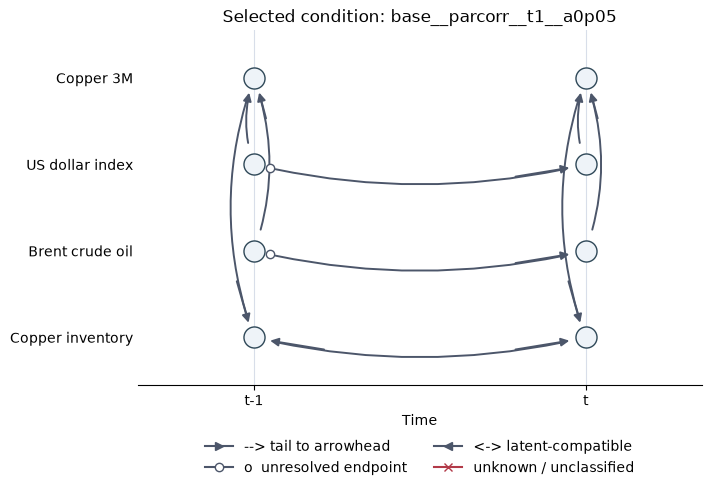

In [27]:
# 그래프는 원래 선정 조건의 전체 PAG입니다. 통과 간선만 잘라 만든 새 PAG가 아닙니다.
search_good_config_ids = set(search_good_links["config_id"]) if not search_good_links.empty else set()
for config_id in SEARCH_DOCUMENT["frozen_selection"] or []:
    if config_id not in search_good_config_ids:
        continue
    full_record = next(r for r in SEARCH_DOCUMENT["attempts"]
                       if r["phase"] == "validation" and r["window"] == "full133"
                       and r["config_id"] == config_id and r["status"] == "complete")
    display(Markdown(f"**조건:** `{config_id}` — 아래 그림의 모든 간선이 안정성 기준을 통과했다는 뜻은 아닙니다. 통과 관계는 앞 표를 따릅니다."))
    plot_pag(np.asarray(full_record["graph"]), full_record["variables"],
             title=f"Selected condition: {config_id}")
    plt.show()


In [28]:
SEARCH_REVIEW_MANIFEST = "b834fa0dd5af075b17619d35d048f3b7096eed0c237ef9ba619f1f9de6743f72"
if SEARCH_DOCUMENT["manifest_hash"] == SEARCH_REVIEW_MANIFEST and SEARCH_DOCUMENT["status"] == "complete":
    display(Markdown("""
### 이번 탐색에서 남길 결과

**역사적 자료에서 브렌트유와 구리 월간 변화의 동시점 양의 조건부 연관이 가장 재현성이 높았습니다.**
최종 연결 안정성 기준을 통과한 설정은 기존 변수군
(구리 3개월물 + 달러지수 + 브렌트유 + LME 재고), LPCMCI + ParCorr,
최대시차 1개월, alpha=0.05입니다. 해당 연결의 lag는 **0개월**입니다.

| 점검 | 브렌트유–구리 연결 |
|---|---|
| 개발의 72·84·96개월 창 | 5/5에서 같은 양의 부호로 검출 |
| 연도 블록 제외 | 11/11에서 같은 양의 부호로 검출 |
| 2020년·2022년을 각각 제외 | 두 경우 모두 연결·부호 유지 |
| 108·120개월 창 / 현물 / 최대시차 3 | 6/6에서 같은 양의 부호로 검출 |
| 시간 정렬을 흐트러뜨린 대조 | 0/19에서 검출 |
| 2023-01–2026-01 후기 구간 | 미검출; 37개 원자료 월에서 실제 CI 표본은 30개 |

기존 변수군에서 검정·alpha·최대시차를 달리한 12개 조건 모두에서도
이 연결은 개발 안정성 기준을 만족했습니다. 이것은 관계가 특정 alpha 하나에만 의존하지 않는다는 근거이며,
각 조건의 미래 일반화나 참 인과성을 보증하지 않습니다.

**방향까지 안정적으로 복원한 것은 아닙니다.** 브렌트유가 구리의 조상이라는 정확한 방향은
연도 제외에서 8/11에 그쳤고, 2020년을 제외하면 양 끝점이 미확정인 `o-o`가 됩니다.
후기 구간에서의 미검출은 검정력 부족이나 구조 변화 모두와 양립합니다.
따라서 이번 탐색에서 최종 방향 기준을 통과한 관계는 **0개**이며, 검증된 시장 DAG로 사용하면 안 됩니다.

경제적 해석은 공통 산업 경기·위험선호와 에너지 비용 경로에 부합합니다.
다만 이것만으로 ‘유가를 변화시키면 구리 가격이 얼마 변한다’는 추론은 할 수 없습니다.
[IMF의 금속·원유 해설](https://www.imf.org/en/blogs/articles/2015/09/14/metals-and-oil-a-tale-of-two-commodities)

**분석창 판단:** 72·84·96개월 창에서 연결은 모두 유지되어 특정 길이 하나가 최적이라고 고를 근거는 없습니다.
역사적 탐색에서는 여러 길이를 함께 비교하고, 전체 자료의 결과를 참조하는 편이 타당합니다.
후기 37개월의 결과를 긴 과거 창으로 덮어서 현재도 같은 구조라고 주장하지 않습니다.
"""))
else:
    display(Markdown("이 실험 서명에 대한 결과 해석은 아직 없습니다. 새 실행 결과를 Codex에서 검토해야 합니다."))



### 이번 탐색에서 남길 결과

**역사적 자료에서 브렌트유와 구리 월간 변화의 동시점 양의 조건부 연관이 가장 재현성이 높았습니다.**
최종 연결 안정성 기준을 통과한 설정은 기존 변수군
(구리 3개월물 + 달러지수 + 브렌트유 + LME 재고), LPCMCI + ParCorr,
최대시차 1개월, alpha=0.05입니다. 해당 연결의 lag는 **0개월**입니다.

| 점검 | 브렌트유–구리 연결 |
|---|---|
| 개발의 72·84·96개월 창 | 5/5에서 같은 양의 부호로 검출 |
| 연도 블록 제외 | 11/11에서 같은 양의 부호로 검출 |
| 2020년·2022년을 각각 제외 | 두 경우 모두 연결·부호 유지 |
| 108·120개월 창 / 현물 / 최대시차 3 | 6/6에서 같은 양의 부호로 검출 |
| 시간 정렬을 흐트러뜨린 대조 | 0/19에서 검출 |
| 2023-01–2026-01 후기 구간 | 미검출; 37개 원자료 월에서 실제 CI 표본은 30개 |

기존 변수군에서 검정·alpha·최대시차를 달리한 12개 조건 모두에서도
이 연결은 개발 안정성 기준을 만족했습니다. 이것은 관계가 특정 alpha 하나에만 의존하지 않는다는 근거이며,
각 조건의 미래 일반화나 참 인과성을 보증하지 않습니다.

**방향까지 안정적으로 복원한 것은 아닙니다.** 브렌트유가 구리의 조상이라는 정확한 방향은
연도 제외에서 8/11에 그쳤고, 2020년을 제외하면 양 끝점이 미확정인 `o-o`가 됩니다.
후기 구간에서의 미검출은 검정력 부족이나 구조 변화 모두와 양립합니다.
따라서 이번 탐색에서 최종 방향 기준을 통과한 관계는 **0개**이며, 검증된 시장 DAG로 사용하면 안 됩니다.

경제적 해석은 공통 산업 경기·위험선호와 에너지 비용 경로에 부합합니다.
다만 이것만으로 ‘유가를 변화시키면 구리 가격이 얼마 변한다’는 추론은 할 수 없습니다.
[IMF의 금속·원유 해설](https://www.imf.org/en/blogs/articles/2015/09/14/metals-and-oil-a-tale-of-two-commodities)

**분석창 판단:** 72·84·96개월 창에서 연결은 모두 유지되어 특정 길이 하나가 최적이라고 고를 근거는 없습니다.
역사적 탐색에서는 여러 길이를 함께 비교하고, 전체 자료의 결과를 참조하는 편이 타당합니다.
후기 37개월의 결과를 긴 과거 창으로 덮어서 현재도 같은 구조라고 주장하지 않습니다.


In [29]:
assert SEARCH_DOCUMENT["status"] == "complete"
assert SEARCH_DOCUMENT["frozen_selection"] is not None
assert all(r["status"] == "complete" for r in SEARCH_DOCUMENT["attempts"])
assert len([r for r in SEARCH_DOCUMENT["attempts"] if r["phase"] == "dev"]) == 360
assert baseline.signature == SEARCH_BASELINE_SIGNATURE
assert list(VARIABLES) == SEARCH_BASELINE_VARIABLES
assert sha256(DATA_PATH.read_bytes()).hexdigest() == INPUT_HASH
assert search_definition_sha256(ROOT / "02. prototype.ipynb") == SEARCH_DOCUMENT["manifest"]["search_definition_sha256"]
display(Markdown(
    "검증 완료: 개발 이후 선정 고정 · 전체 시행 기록 보존 · 원본 CSV/기본 분석 보존 · "
    "LLM 보완 제외 · 실행 실패 없음. 반복 빈도는 인과 확률이 아닙니다."
))


검증 완료: 개발 이후 선정 고정 · 전체 시행 기록 보존 · 원본 CSV/기본 분석 보존 · LLM 보완 제외 · 실행 실패 없음. 반복 빈도는 인과 확률이 아닙니다.

### 탐색 설계의 근거

- [Gerhardus & Runge, LPCMCI (NeurIPS 2020)](https://proceedings.neurips.cc/paper_files/paper/2020/file/94e70705efae423efda1088614128d0b-Paper.pdf): 표본 수·조건집합 차원·정상성 및 유한 표본의 한계. 위 월수나 80% 기준을 보증하는 논문이 아닙니다.
- [Tigramite RobustParCorr](https://jakobrunge.github.io/tigramite/#tigramite.independence_tests.robust_parcorr.RobustParCorr): 주변분포 변환과 조건부 부분상관의 의미.
- [Meinshausen & Bühlmann, Stability Selection](https://arxiv.org/html/0809.2932v2): 선택 빈도에 의한 안정성 평가 원리. 본 실험의 겹치는 창·블록 삭제·PAG 빈도에 논문의 오류율 보장을 그대로 적용하지 않습니다.

## 방법론·해석의 근거

- [Tigramite / LPCMCI 공식 구현](https://jakobrunge.github.io/tigramite/_modules/tigramite/lpcmci.html): 사전 제약, PAG 끝점, p/val 출력 의미.
- [Gerhardus & Runge, NeurIPS 2020](https://proceedings.neurips.cc/paper/2020/file/94e70705efae423efda1088614128d0b-Paper.pdf): LPCMCI의 가정과 유한 표본에서의 한계.
- [Long et al., Causal Discovery with Language Models as Imperfect Experts](https://arxiv.org/html/2307.02390v1): 불완전한 도메인 전문가를 통한 방향 보완. 현재 구리 데이터에 대한 정확도 보증은 아님.
- [LME 금융 투자자 설명](https://www.lme.com/en/education/online-resources/lme-digest/financial-investors-on-the-lme): 3개월물 선택의 시장 기준 근거.
- [LME 공식 가격](https://www.lme.com/market-data/lme-reference-prices/lme-official-price): 현물·3개월물 및 공식 결제가격 구분. 보유 CSV의 정확한 집계 정의는 미확인.
- [OECD CLI FAQ](https://www.oecd.org/en/data/insights/data-explainers/2024/04/composite-leading-indicators-frequently-asked-questions.html): 지표 개정·빈티지·구성 특성.

원본 과제와 이 대화에서 확정한 범위를 따릅니다. 인과효과 추정, what-if, 예측, UI, 자동 LLM 연동은 후속 작업입니다.